# Market Regime Detection System
### A hands-on quant research notebook — EURUSD H1 + 12 real MT5 strategies

**Goal.** Learn how a quant researcher answers one question: *does knowing the market
environment change how I should trade?* You will build the whole stack yourself — data,
features, unsupervised regime models, strategy evaluation, and a walk-forward allocation
test — and you will be able to change any assumption and re-run it.

**What is inside**

| Part | Question it answers | What you build |
|---|---|---|
| 1 | What data do I have, and is it clean? | OHLCV pipeline, returns, stylized facts |
| 2 | How do I describe the environment numerically? | Volatility, ATR, ADX, trend strength, efficiency ratio |
| 3 | Can I partition the market with K-means? | Feature scaling, k selection, stability, transition matrix |
| 4 | Can a latent-state model do better? | A Gaussian HMM from scratch: forward–backward, Baum–Welch, Viterbi |
| 5 | What actually differs between regimes? | Regime profiles, statistical tests, durations |
| 6 | How did my real strategies behave? | Reconstruction of equity curves from MT5 deals |
| 7 | Which strategy works in which regime? | Strategy × regime Sharpe/P&L tables, rank stability |
| 8 | Does regime information improve allocation? | Walk-forward backtest, costs, bootstrap confidence intervals |
| 9 | How do I test *my* hypothesis? | An experiment harness with caching |

**Data provenance.** `data/EURUSD_H1.csv` is H1 OHLCV exported from your MetaTrader 5
terminal (2022-01-03 → 2026-11-20). `data/strategies_EURUSD_H1.csv` holds the deal history of
12 strategies from your MT5 backtester (batch #192, EURUSD H1, 2022-01-01 → 2026-11-21,
100,000 USD deposit). The notebook ships with them, so it runs offline.

**How to use this notebook**

1. Run every cell top-to-bottom once, without changing anything. Read the outputs.
2. Go back to a **Try it** box, change *one* parameter, and re-run that section.
3. Keep a lab notebook: write down the hypothesis *before* you look at the result.
4. Treat every good-looking result as guilty until proven innocent (Part 9 explains how).

> **Educational use only.** Nothing here is investment advice. A backtest is a hypothesis,
> not evidence. Parts 8–9 show how easily regime research fools its author.

## 0. Setup

Three things happen here: imports, a single configuration dictionary, and small helpers used
everywhere else. Keeping the configuration in one place is deliberate — a research notebook
that scatters magic numbers across 60 cells is not reproducible.

**Annualisation.** The data is hourly. FX trades roughly 24 hours × 5 days, so we use
`24 × 252 = 6,048` bars per year. This slightly overstates a calendar year (FX actually has
~6,240 hourly bars), which makes annualised numbers a little conservative. Consistency
matters more than the exact constant.

In [1]:
from __future__ import annotations

import json
import math
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.special import logsumexp
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

try:  # notebook-only; keeps the cell valid if executed as plain Python
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# --- paths -----------------------------------------------------------------
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

# --- one config to rule them all -------------------------------------------
CONFIG = {
    "symbol": "EURUSD",
    "timeframe": "H1",
    "is_end": "2025-01-01",      # in-sample / out-of-sample split
    "bars_per_year": 24 * 252,   # hourly FX bars
    "n_regimes": 3,              # default K for both models
    "seed": 7,
}

BARS_PER_YEAR = CONFIG["bars_per_year"]

# Colour language used consistently: calm -> trend -> choppy -> crisis.
REGIME_COLORS = ["#2E7D6B", "#3B7DD8", "#D9922B", "#C0392B", "#7B5EA7", "#5D6D7E"]
REGIME_LIGHT = ["#A8D5C8", "#AFC8F0", "#F2D3A0", "#E8B4AE", "#CDBFE3", "#C9D1D6"]

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "font.family": "DejaVu Sans",
})


def savefig(fig, name: str, tight: bool = True) -> None:
    """Save a figure into ./figures so the notebook leaves an audit trail."""
    if tight:
        fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight")


def max_drawdown(equity: pd.Series) -> float:
    """Worst peak-to-trough decline of an equity curve (a negative number)."""
    equity = equity.dropna()
    return float((equity / equity.cummax() - 1.0).min())


def perf_stats(returns: pd.Series, freq: int = BARS_PER_YEAR, name: str = "") -> pd.Series:
    """Standard performance statistics from a simple-return series."""
    r = returns.dropna()
    if len(r) == 0 or r.std() == 0:
        return pd.Series(dtype=float, name=name)
    equity = (1.0 + r).cumprod()
    years = len(r) / freq
    cagr = float(equity.iloc[-1] ** (1.0 / years) - 1.0) if years > 0 else np.nan
    vol = float(r.std() * np.sqrt(freq))
    sharpe = float(r.mean() / r.std() * np.sqrt(freq))
    downside = r[r < 0].std()
    sortino = float(r.mean() * freq / (downside * np.sqrt(freq))) if downside and downside > 0 else np.nan
    mdd = max_drawdown(equity)
    return pd.Series({
        "CAGR": cagr,
        "Vol": vol,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "MaxDD": mdd,
        "Calmar": cagr / abs(mdd) if mdd < 0 else np.nan,
        "HitRate": float((r > 0).mean()),
        "Bars": len(r),
    }, name=name)


def paint_regimes(ax, index, labels, colors=REGIME_COLORS, alpha=0.20, y0=None, y1=None):
    """Shade the background of an axis by a discrete regime label series."""
    idx = pd.DatetimeIndex(index)
    if idx.tz is not None:
        idx = idx.tz_convert("UTC").tz_localize(None)
    x = mdates.date2num(idx.to_pydatetime())
    y0 = ax.get_ylim()[0] if y0 is None else y0
    y1 = ax.get_ylim()[1] if y1 is None else y1
    labels = np.asarray(labels)
    for k in np.unique(labels):
        mask = labels == k
        ax.fill_between(x, y0, y1, where=mask, color=colors[int(k) % len(colors)],
                        alpha=alpha, linewidth=0, step="post", zorder=0)


def fmt_pct(x, _=None):
    return f"{x:.0%}"


def fmt_bps(x, _=None):
    return f"{x:.0f}"


print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", __import__("sklearn").__version__)
print("root:", ROOT)
print("bars per year:", BARS_PER_YEAR)

pandas 3.0.5 | numpy 2.4.6 | sklearn 1.9.0
root: C:\Users\DAT\Desktop\VSCode\Quant_Learning
bars per year: 6048


**Read the setup output.** If `root` is not the folder that contains `data/`, stop and fix the
working directory before continuing — every path below depends on it.

Next we load the price file and inspect it like an auditor, not like a user. Most regime
research fails here, silently: duplicate bars, weekend bars, price spikes from a bad feed, or
a timezone shift. Those artefacts look exactly like "regimes" to an unsupervised model.

## 1. Data — collect, inspect, and distrust

### 1.1 What OHLCV actually is

Each row is one **bar** (here: one hour). `open`/`high`/`low`/`close` are the first, maximum,
minimum and last traded prices inside that hour; `tick_volume` counts price updates, not
contracts. A bar is a *summary*, not a path: two different intrabar paths can produce identical
OHLC. Every backtest on bars inherits that ambiguity.

### 1.2 Timezone discipline

MT5 reports server time, which is usually not UTC and shifts with daylight saving. We store
everything as **UTC** and never mix naive and aware timestamps. If you skip this, your
"overnight" regime is really "whatever the broker's DST rule did".

In [2]:
def _synthetic_prices(n: int = 30_000, seed: int = 11) -> pd.DataFrame:
    """Fallback only: a 3-state Markov volatility process + fat-tailed returns.

    This exists so the notebook still teaches the pipeline if the CSV is missing.
    It is NOT a substitute for real data.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2022-01-03", periods=n, freq="h", tz="UTC")
    # regime chain: calm / normal / crisis
    P = np.array([[0.995, 0.0045, 0.0005],
                  [0.006, 0.990, 0.004],
                  [0.010, 0.040, 0.950]])
    state = np.zeros(n, dtype=int)
    for t in range(1, n):
        state[t] = rng.choice(3, p=P[state[t - 1]])
    sigma = np.array([0.00045, 0.0009, 0.0022])[state]
    mu = np.array([0.000004, 0.000002, -0.00003])[state]
    shocks = rng.standard_t(df=5, size=n) / np.sqrt(5 / 3)
    ret = mu + sigma * shocks
    close = 1.10 * np.exp(np.cumsum(ret))
    # build plausible OHLC around the close path
    noise = np.abs(rng.normal(0, 1, size=(n, 2))) * sigma[:, None] * close[:, None]
    open_ = np.r_[close[0], close[:-1]] * (1 + rng.normal(0, 0.0001, n))
    high = np.maximum(open_, close) + noise[:, 0]
    low = np.minimum(open_, close) - noise[:, 1]
    return pd.DataFrame({"open": open_, "high": high, "low": low, "close": close,
                         "tick_volume": rng.integers(100, 5000, n),
                         "spread": rng.integers(0, 25, n)}, index=idx)


def load_prices(path: Path = DATA / "EURUSD_H1.csv") -> tuple[pd.DataFrame, str]:
    """Load OHLCV from CSV, then MT5, then synthetic. Returns (frame, source)."""
    path = Path(path)
    if path.exists():
        df = pd.read_csv(path, parse_dates=["time"])
        source = path.name
    else:
        try:
            import MetaTrader5 as mt5
            if not mt5.initialize():
                raise RuntimeError(mt5.last_error())
            rates = mt5.copy_rates_range(
                CONFIG["symbol"], mt5.TIMEFRAME_H1,
                pd.Timestamp("2022-01-01", tz="UTC").to_pydatetime(),
                pd.Timestamp.now(tz="UTC").to_pydatetime(),
            )
            mt5.shutdown()
            df = pd.DataFrame(rates)
            df["time"] = pd.to_datetime(df["time"], unit="s", utc=True)
            source = "MetaTrader5 live export"
        except Exception as exc:  # noqa: BLE001 - fallback is intentional
            print(f"[warn] no price file and no MT5 ({exc}); using synthetic data.")
            df, source = _synthetic_prices(), "synthetic"

    df["time"] = pd.to_datetime(df["time"], utc=True)
    df = df.set_index("time").sort_index()
    df = df[~df.index.duplicated(keep="first")]
    cols = ["open", "high", "low", "close", "tick_volume", "spread"]
    for c in cols:
        if c not in df:
            df[c] = np.nan
    df = df[cols].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=["open", "high", "low", "close"])
    df = df[(df[["open", "high", "low", "close"]] > 0).all(axis=1)]
    return df, source


prices, PRICE_SOURCE = load_prices()
print(f"source: {PRICE_SOURCE}")
print(f"rows: {len(prices):,}   range: {prices.index.min()} -> {prices.index.max()}")
prices.head()

source: EURUSD_H1.csv
rows: 30,451   range: 2022-01-03 00:00:00+00:00 -> 2026-11-20 23:00:00+00:00


,open,high,low,close,tick_volume,spread
time,,,,,,
2022-01-03 00:00:00+00:00,1.137,1.137,1.137,1.137,0,0
2022-01-03 01:00:00+00:00,1.138,1.138,1.137,1.137,0,0
2022-01-03 02:00:00+00:00,1.137,1.138,1.136,1.136,0,0
2022-01-03 03:00:00+00:00,1.136,1.137,1.135,1.136,0,0
2022-01-03 04:00:00+00:00,1.136,1.136,1.134,1.134,0,0


### 1.3 Data-quality audit

Five checks catch most silent data bugs:

1. **Duplicates** — two bars with the same timestamp double-count a return.
2. **OHLC integrity** — `high` must be ≥ both `open` and `close`; `low` ≤ both.
3. **Gaps** — FX has a weekend gap (~48h). Any *other* multi-hour gap is missing data.
4. **Stale prices** — a long run of identical closes means the feed froze.
5. **Outliers** — a 5% hourly move in EURUSD is either a real event (CPI, intervention) or a
   bad tick. You must decide which, not the model.

In [3]:
def data_audit(df: pd.DataFrame) -> pd.DataFrame:
    idx = df.index
    gaps = pd.Series(idx).diff().dropna()
    hours = gaps.dt.total_seconds() / 3600
    o, h, l, c = df["open"], df["high"], df["low"], df["close"]
    ret = np.log(c).diff()
    checks = {
        "rows": len(df),
        "first bar": str(idx.min()),
        "last bar": str(idx.max()),
        "duplicate timestamps": int(idx.duplicated().sum()),
        "OHLC violations (high)": int((h < np.maximum(o, c) - 1e-12).sum()),
        "OHLC violations (low)": int((l > np.minimum(o, c) + 1e-12).sum()),
        "bars > 3h gap (excl. weekend)": int(((hours > 3) & (hours < 40)).sum()),
        "max gap (hours)": round(float(hours.max()), 1),
        "longest flat-close run": int((c.diff() == 0).astype(int).groupby((c.diff() != 0).cumsum()).sum().max()),
        "largest abs 1h return": f"{ret.abs().max():.2%}",
        "annualised vol": f"{ret.std() * np.sqrt(BARS_PER_YEAR):.1%}",
        "avg bars per trading day": round(len(df) / max(1, idx.normalize().nunique()), 1),
    }
    return pd.Series(checks, name="value").to_frame()


display(data_audit(prices))

# Where are the biggest moves? Real macro events usually cluster at fixed times.
top = np.log(prices["close"]).diff().abs().nlargest(8).index
prices.loc[top, ["open", "high", "low", "close"]].assign(
    ret_1h=np.log(prices["close"]).diff().loc[top]
).sort_index()

,value
rows,30451
first bar,2022-01-03 00:00:00+00:00
last bar,2026-11-20 23:00:00+00:00
duplicate timestamps,0
OHLC violations (high),0
OHLC violations (low),0
bars > 3h gap (excl. weekend),5
max gap (hours),73.000
longest flat-close run,2
largest abs 1h return,1.74%


,open,high,low,close,ret_1h
time,,,,,
2022-02-28 00:00:00+00:00,1.114,1.116,1.114,1.115,-0.011
2022-09-13 15:00:00+00:00,1.018,1.018,1.003,1.004,-0.014
2022-09-26 03:00:00+00:00,0.968,0.969,0.955,0.957,-0.012
2022-11-10 15:00:00+00:00,0.995,1.016,0.994,1.012,0.017
2024-12-18 21:00:00+00:00,1.049,1.049,1.037,1.038,-0.010
2025-02-03 00:00:00+00:00,1.024,1.026,1.024,1.025,-0.011
2025-05-12 10:00:00+00:00,1.122,1.122,1.110,1.111,-0.010
2025-08-01 15:00:00+00:00,1.140,1.156,1.139,1.155,0.012


A well-behaved EURUSD H1 file should show: no duplicates, no OHLC violations, a handful of
large gaps (weekends/holidays), and annualised volatility around 6–10%. If your audit is much
worse, fix the data before modelling — unsupervised models will happily cluster your data bugs.

### 1.4 Returns and the stylised facts you must know

We work with **log returns** `r_t = ln(P_t / P_{t-1})` because they add over time and are
approximately symmetric. Simple returns compound; log returns sum. For small moves the
difference is negligible, for large ones it matters.

Three facts drive everything that follows:

* **Volatility clusters** — big moves follow big moves. That is the raw material of regimes.
* **Fat tails** — returns are far more extreme than a normal distribution predicts.
* **Near-zero autocorrelation** — direction is almost unpredictable at hourly frequency;
  *magnitude* is very predictable.

,value
bars,"30,450.000"
ann. mean,-0.007
ann. vol,0.078
skew,0.084
excess kurtosis,15.978
min,-0.014
max,0.017
lag-1 autocorr,-0.019
lag-24 autocorr,0.003
Jarque-Bera p,0.000


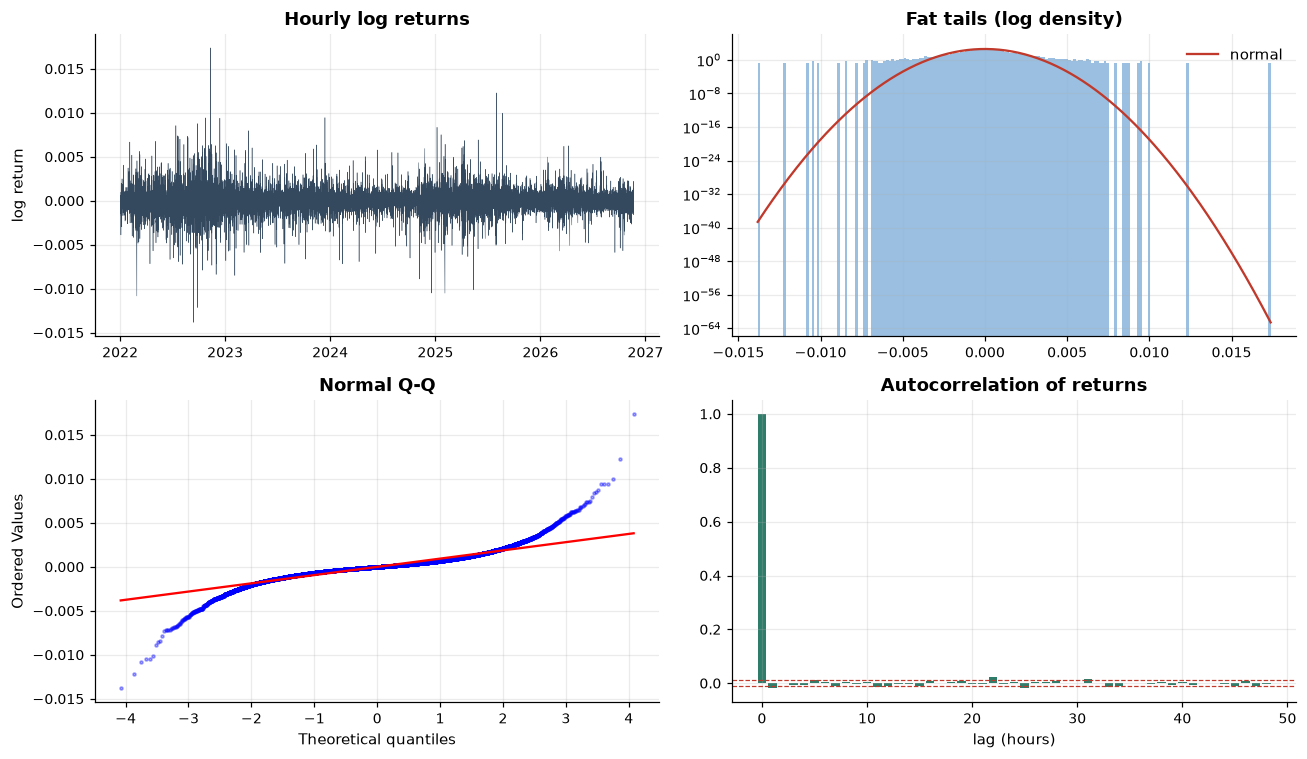

In [4]:
prices["log_ret"] = np.log(prices["close"]).diff()
prices["simple_ret"] = prices["close"].pct_change(fill_method=None)
r = prices["log_ret"].dropna()

def acf(x: pd.Series, nlags: int = 48) -> np.ndarray:
    x = np.asarray(x.dropna(), dtype=float)
    x = x - x.mean()
    denom = float((x * x).sum())
    return np.array([1.0] + [float((x[:-k] * x[k:]).sum() / denom) for k in range(1, nlags + 1)])

summary = pd.Series({
    "bars": len(r),
    "ann. mean": r.mean() * BARS_PER_YEAR,
    "ann. vol": r.std() * np.sqrt(BARS_PER_YEAR),
    "skew": stats.skew(r),
    "excess kurtosis": stats.kurtosis(r),
    "min": r.min(),
    "max": r.max(),
    "lag-1 autocorr": r.autocorr(1),
    "lag-24 autocorr": r.autocorr(24),
    "Jarque-Bera p": stats.jarque_bera(r).pvalue,
})
display(summary.to_frame("value"))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
ax = axes[0, 0]
ax.plot(r.index, r.values, lw=0.3, color="#34495E")
ax.set_title("Hourly log returns")
ax.set_ylabel("log return")

ax = axes[0, 1]
ax.hist(r, bins=200, density=True, color="#8FB8DE", edgecolor="none", alpha=0.9)
grid = np.linspace(r.min(), r.max(), 400)
ax.plot(grid, stats.norm.pdf(grid, r.mean(), r.std()), color="#C0392B", lw=1.5, label="normal")
ax.set_yscale("log")
ax.set_title("Fat tails (log density)")
ax.legend()

ax = axes[1, 0]
stats.probplot(r, dist="norm", plot=ax)
ax.get_lines()[0].set_markersize(2)
ax.get_lines()[0].set_alpha(0.35)
ax.set_title("Normal Q-Q")

ax = axes[1, 1]
a = acf(r, 48)
ci = 1.96 / np.sqrt(len(r))
ax.bar(range(len(a)), a, color="#2E7D6B", width=0.8)
ax.axhline(ci, color="#C0392B", ls="--", lw=0.8)
ax.axhline(-ci, color="#C0392B", ls="--", lw=0.8)
ax.set_title("Autocorrelation of returns")
ax.set_xlabel("lag (hours)")

savefig(fig, "01_returns_stylized_facts")
plt.show()

**What to notice.** The Q-Q plot bends away from the line in both tails: the normal
distribution cannot produce these extremes. Yet the ACF bars barely leave the confidence
band — direction is close to a coin flip, while volatility (next section) is highly
persistent. That asymmetry is the entire reason regime models focus on *volatility and trend
character*, not on predicting the next return.

> **Try it.** Compute the ACF of `r.abs()` or `r**2`. You will see slow, significant decay —
> that is volatility clustering, the signal the HMM will later formalise.

## 2. Features — turning a price path into a market description

A regime model is only as good as its inputs. We build five features, each answering a
different question:

| Feature | Question | Formula / intuition |
|---|---|---|
| `vol_24` | How fast is price moving? | Rolling std of hourly log returns over 24 bars, annualised. |
| `atr_pct` | How large is a typical bar? | Wilder ATR(14) ÷ close. A range-based volatility proxy that includes gaps. |
| `adx_14` | Is there a directional trend? | Wilder's Average Directional Index: smoothed |+DI − −DI| ÷ (+DI + −DI). 0–100. |
| `trend_r2_48` | How *clean* is the trend? | R² of a regression of log price on time over 48 bars. 0 = noise, 1 = straight line. |
| `er_24` | How efficient is the move? | Kaufman efficiency ratio: |P_t − P_{t−24}| ÷ Σ|ΔP|. 0 = all noise, 1 = monotone. |

### Why these and not returns?

Returns are nearly unpredictable (Part 1), but *volatility* and *trend character* are highly
persistent. Clustering on returns would produce noise clusters that change every bar.
Clustering on volatility/trend features produces **states that last** — which is what a regime
is supposed to be.

### The look-ahead rule

Every feature at bar `t` uses only bars up to and including `t`. That is legal: at the close of
bar `t` you know the close. The danger is using *future* bars — a centred moving average, a
full-sample scaler, or a HMM smoothed path — and then pretending you could have traded on it.
We will keep those distinctions explicit.

In [5]:
def wilder(series: pd.Series, n: int) -> pd.Series:
    """Wilder's smoothing = EMA with alpha = 1/n (the original RSI/ATR/ADX recursion)."""
    return series.ewm(alpha=1.0 / n, adjust=False, min_periods=n).mean()


def true_range(df: pd.DataFrame) -> pd.Series:
    prev_close = df["close"].shift(1)
    return pd.concat(
        [df["high"] - df["low"], (df["high"] - prev_close).abs(), (df["low"] - prev_close).abs()],
        axis=1,
    ).max(axis=1)


def atr(df: pd.DataFrame, n: int = 14) -> pd.Series:
    return wilder(true_range(df), n)


def adx(df: pd.DataFrame, n: int = 14) -> tuple[pd.Series, pd.Series, pd.Series]:
    """Wilder's ADX plus the two directional indicators."""
    up, down = df["high"].diff(), -df["low"].diff()
    plus_dm = pd.Series(np.where((up > down) & (up > 0), up, 0.0), index=df.index)
    minus_dm = pd.Series(np.where((down > up) & (down > 0), down, 0.0), index=df.index)
    atr_n = wilder(true_range(df), n)
    plus_di = 100.0 * wilder(plus_dm, n) / atr_n
    minus_di = 100.0 * wilder(minus_dm, n) / atr_n
    dx = 100.0 * (plus_di - minus_di).abs() / (plus_di + minus_di).replace(0, np.nan)
    return wilder(dx, n), plus_di, minus_di


def rolling_trend_r2(close: pd.Series, n: int = 48) -> pd.Series:
    """R^2 of log(price) regressed on time, computed in a fully vectorised way.

    For a window ending at t, x runs 0..n-1. Sum(x*y) is obtained from the rolling
    sum of (global_index * y) minus the window start times the rolling sum of y.
    """
    y = np.log(close.astype(float))
    idx = np.arange(len(y))
    sx = n * (n - 1) / 2.0
    sxx = (n - 1) * n * (2 * n - 1) / 6.0
    sy = y.rolling(n).sum()
    syy = (y * y).rolling(n).sum()
    siy = (y * idx).rolling(n).sum()
    sxy = siy - (idx - n + 1) * sy
    numerator = (n * sxy - sx * sy) ** 2
    denominator = (n * sxx - sx * sx) * (n * syy - sy * sy)
    return (numerator / denominator).clip(0.0, 1.0)


def efficiency_ratio(close: pd.Series, n: int = 24) -> pd.Series:
    direction = close.diff(n).abs()
    path = close.diff().abs().rolling(n).sum()
    return direction / path.replace(0, np.nan)


def build_features(df: pd.DataFrame, n_vol: int = 24, n_atr: int = 14,
                   n_adx: int = 14, n_trend: int = 48) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index)
    out["log_ret"] = np.log(df["close"]).diff()
    out["vol_24"] = out["log_ret"].rolling(n_vol).std() * np.sqrt(BARS_PER_YEAR)
    out["atr_pct"] = atr(df, n_atr) / df["close"] * 100.0
    out["adx_14"], out["plus_di"], out["minus_di"] = adx(df, n_adx)
    out["trend_r2_48"] = rolling_trend_r2(df["close"], n_trend)
    out["er_24"] = efficiency_ratio(df["close"], n_vol)
    out["range_pct"] = ((df["high"] - df["low"]) / df["close"] * 100.0).rolling(n_vol).mean()
    return out


FEATURES = ["vol_24", "atr_pct", "adx_14", "trend_r2_48", "er_24"]

features = build_features(prices).replace([np.inf, -np.inf], np.nan)
features = features.dropna(subset=FEATURES)
print(f"feature rows: {len(features):,}  (lost {len(prices) - len(features)} warm-up bars)")
features[FEATURES].describe().T

feature rows: 30,404  (lost 47 warm-up bars)


,count,mean,std,min,25%,50%,75%,max
vol_24,"30,404.000",0.070,0.034,0.015,0.047,0.062,0.085,0.313
atr_pct,"30,404.000",0.130,0.051,0.043,0.094,0.118,0.154,0.501
adx_14,"30,404.000",26.295,10.804,6.663,18.029,24.242,32.624,72.327
trend_r2_48,"30,404.000",0.433,0.290,0.000,0.154,0.444,0.699,0.967
er_24,"30,404.000",0.225,0.160,0.000,0.094,0.197,0.330,0.825


The first 48 bars are lost to the longest lookback — unavoidable. Note the units: volatility is
annualised, ATR and range are in percent of price, ADX and R² are unitless. K-means uses
Euclidean distance, so **units are not cosmetic**: a feature measured in hundreds would
dominate one measured in tenths. Standardisation is not optional.

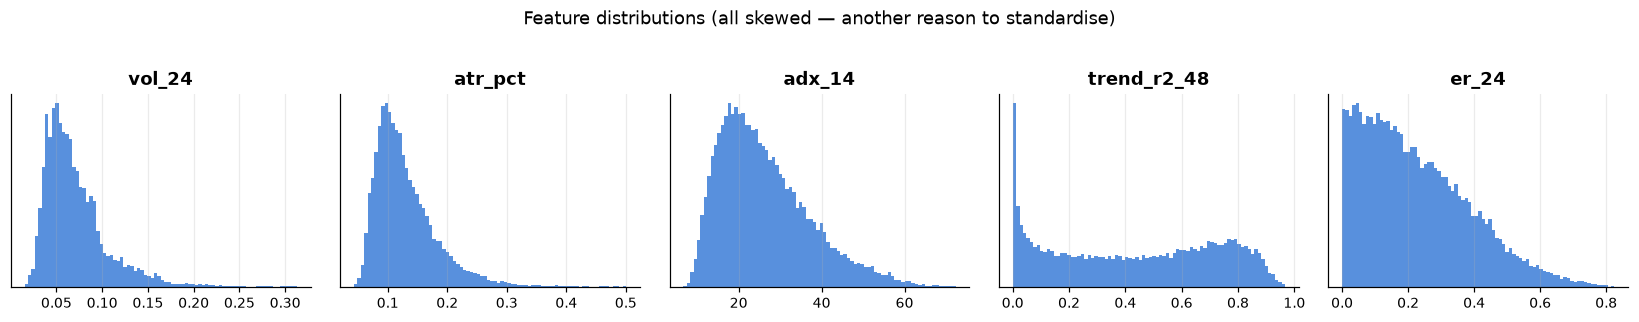

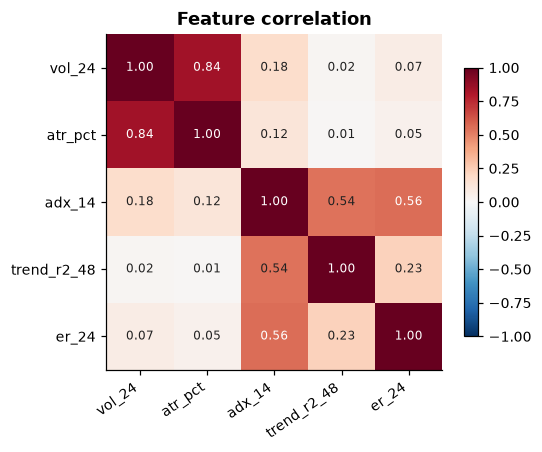

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(15, 2.8))
for ax, col in zip(axes, FEATURES):
    ax.hist(features[col], bins=80, color="#3B7DD8", alpha=0.85, edgecolor="none")
    ax.set_title(col)
    ax.set_yticks([])
fig.suptitle("Feature distributions (all skewed — another reason to standardise)", y=1.03)
savefig(fig, "02_feature_distributions")
plt.show()

corr = features[FEATURES].corr()
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=35, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.55 else "#222", fontsize=8)
ax.set_title("Feature correlation")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
savefig(fig, "02_feature_correlation")
plt.show()

**Collinearity warning.** `vol_24`, `atr_pct` and `range_pct` measure nearly the same thing
(ρ ≈ 0.8–0.95). Feeding all of them to K-means silently gives volatility triple weight. That is
a modelling choice, not a law — and it is why we keep the set small.

### Train / test split and scaling

We fit the scaler **only on the in-sample period** (`before 2025-01-01`) and apply it to the
out-of-sample period. Fitting on the full sample would leak the future distribution into the
past — a subtle leak, but exactly the kind that makes a walk-forward backtest lie.

In [7]:
IS_END = pd.Timestamp(CONFIG["is_end"], tz="UTC")
is_mask = np.asarray(features.index < IS_END)
oos_mask = ~is_mask

scaler = StandardScaler().fit(features.loc[is_mask, FEATURES])
Z_full = scaler.transform(features[FEATURES])
Z = pd.DataFrame(Z_full, index=features.index, columns=FEATURES)

X_is, X_oos = Z_full[is_mask], Z_full[oos_mask]
print(f"in-sample : {X_is.shape[0]:>6,} bars  {features.index[is_mask].min()} -> {features.index[is_mask].max()}")
print(f"out-sample: {X_oos.shape[0]:>6,} bars  {features.index[oos_mask].min()} -> {features.index[oos_mask].max()}")
print("\nstandardised means (in-sample):", np.round(X_is.mean(0), 3))
print("standardised stds  (in-sample):", np.round(X_is.std(0), 3))

in-sample : 18,644 bars  2022-01-04 23:00:00+00:00 -> 2024-12-31 23:00:00+00:00
out-sample: 11,760 bars  2025-01-02 00:00:00+00:00 -> 2026-11-20 23:00:00+00:00

standardised means (in-sample): [ 0. -0.  0.  0. -0.]
standardised stds  (in-sample): [1. 1. 1. 1. 1.]


> **Try it.** Replace `FEATURES` with `["vol_24"]` only and re-run Parts 3–4. You get a
> pure volatility regime model. Then add `adx_14` back. Does the number of "trending" states
> change? This is feature engineering as an experiment, not as taste.

## 3. K-means — the simplest regime partition

### The idea

K-means asks: *given K groups, assign every bar to the group whose centre is closest, and choose
centres so the total squared distance is minimised.*

$$\min_{\{C_k\},\{\mu_k\}} \sum_{k=1}^{K}\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

It is fast, interpretable, and completely ignorant of time. That last property is both its
appeal (no assumptions about persistence) and its weakness (it will happily label one bar
"crisis" and the next "calm").

### What K-means cannot do

* It assumes clusters are roughly spherical and equally sized.
* It has no notion of transition — no `P(regime tomorrow | regime today)`.
* Labels are arbitrary integers; two runs can swap "0" and "1".
* It partitions *feature space*, not *time*: the same regime can appear in many disconnected
  episodes.

We will handle label-switching by ordering clusters by their average volatility, and we will
handle the "no time" problem in Part 4 with a Hidden Markov Model.

In [8]:
def fit_kmeans(X: np.ndarray, k: int, seed: int = 0, n_init: int = 20) -> KMeans:
    return KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(X)


def order_by_vol(labels: np.ndarray, centers: pd.DataFrame, vol_col: str = "vol_24"):
    """Relabel clusters so that 0 = lowest average volatility. Kills label-switching."""
    order = np.argsort(centers[vol_col].values)
    remap = {int(old): int(new) for new, old in enumerate(order)}
    return np.array([remap[int(x)] for x in labels]), remap


def name_regimes(centers: pd.DataFrame, vol_col: str = "vol_24", trend_col: str = "adx_14") -> list[str]:
    """Human-readable names from each cluster's average volatility and trend strength.

    Position in the *ordered* set matters, not a percentile of a continuous distribution:
    with K=3 the labels must be Low / Mid / High, not High / High / High.
    """
    k = len(centers)
    vol_pos = (centers[vol_col].rank(method="first") - 1) / max(1, k - 1)
    trend_pos = (centers[trend_col].rank(method="first") - 1) / max(1, k - 1)
    trend_cut = 0.5 if k <= 2 else 2 / 3

    names = []
    for i in centers.index:
        if vol_pos[i] <= 1 / 3:
            vol_word = "Low-vol"
        elif vol_pos[i] >= 2 / 3:
            vol_word = "High-vol"
        else:
            vol_word = "Mid-vol"
        trend_word = "trend" if trend_pos[i] >= trend_cut else "chop"
        names.append(f"{vol_word} {trend_word}")

    # de-duplicate while keeping order
    seen: dict[str, int] = {}
    out = []
    for n in names:
        seen[n] = seen.get(n, 0) + 1
        out.append(n if seen[n] == 1 else f"{n} {seen[n]}")
    return out


def kmeans_regimes(X: np.ndarray, k: int, feature_names: list[str], seed: int = 0,
                   scaler: StandardScaler | None = None):
    km = fit_kmeans(X, k, seed=seed)
    labels = km.labels_
    centers = pd.DataFrame(km.cluster_centers_, columns=feature_names)
    if scaler is not None:
        centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_),
                               columns=feature_names)
    labels, remap = order_by_vol(labels, centers)
    centers = centers.loc[np.argsort(centers["vol_24"].values)].reset_index(drop=True)
    centers.index.name = "regime"
    names = name_regimes(centers)
    return {"model": km, "labels": labels, "remap": remap, "centers": centers, "names": names}


def transition_matrix(labels: np.ndarray, k: int) -> np.ndarray:
    m = np.zeros((k, k))
    np.add.at(m, (np.asarray(labels[:-1]), np.asarray(labels[1:])), 1.0)
    row = m.sum(1, keepdims=True)
    return np.divide(m, row, out=np.zeros_like(m), where=row > 0)


def run_lengths(labels: np.ndarray) -> np.ndarray:
    labels = np.asarray(labels)
    if len(labels) == 0:
        return np.array([])
    breaks = np.r_[0, np.where(labels[1:] != labels[:-1])[0] + 1, len(labels)]
    return np.diff(breaks)


def regime_table(labels: np.ndarray, names: list[str]) -> pd.DataFrame:
    labels = np.asarray(labels)
    tm = transition_matrix(labels, len(names))
    starts = np.r_[True, labels[1:] != labels[:-1]]
    rows = []
    for k, name in enumerate(names):
        mask = labels == k
        rows.append({
            "regime": k,
            "name": name,
            "share": float(mask.mean()),
            "bars": int(mask.sum()),
            "episodes": int((mask & starts).sum()),
            "avg duration (bars)": 1.0 / max(1e-9, 1.0 - tm[k, k]),
            "persistence P(stay)": float(tm[k, k]),
        })
    return pd.DataFrame(rows).set_index("regime")

### 3.1 Choosing K

Two standard diagnostics:

* **Elbow** — plot within-cluster sum of squares (inertia). It always falls with K; look for the
  bend.
* **Silhouette** — for each point, `(b − a) / max(a, b)` where `a` is the mean distance to its own
  cluster and `b` to the nearest other cluster. Range −1…1; higher is better separated.

Neither is decisive. A regime model is a *lens*, not a truth: choose the K that produces states
you can interpret and that survive out of sample.

,inertia,silhouette
k,,
2,"68,266.633",0.282
3,"51,486.928",0.287
4,"43,973.637",0.236
5,"39,575.735",0.238
6,"35,558.674",0.241
7,"32,862.101",0.236


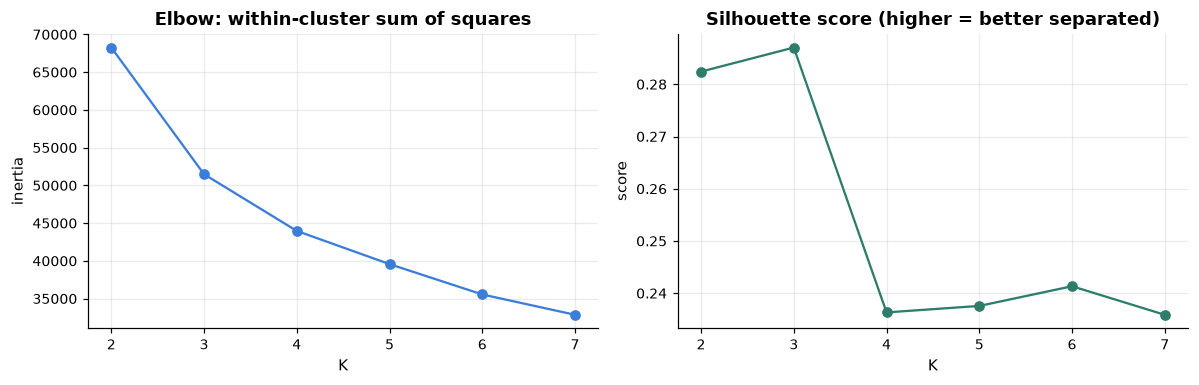

In [9]:
ks = list(range(2, 8))
rows = []
for k in ks:
    km = fit_kmeans(X_is, k, seed=CONFIG["seed"], n_init=10)
    sil = silhouette_score(X_is[::5], km.labels_[::5])
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
selection = pd.DataFrame(rows).set_index("k")
display(selection)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(selection.index, selection["inertia"], "o-", color="#3B7DD8")
axes[0].set(title="Elbow: within-cluster sum of squares", xlabel="K", ylabel="inertia")
axes[1].plot(selection.index, selection["silhouette"], "o-", color="#2E7D6B")
axes[1].set(title="Silhouette score (higher = better separated)", xlabel="K", ylabel="score")
savefig(fig, "03_kmeans_choose_k")
plt.show()

**How to read it.** Inertia falls monotonically — never choose K by its minimum. The silhouette
usually peaks at a small K and then decays; here the peak is a guide, not an answer. We will
use **K = 3** for both models so the comparison is fair, then test K = 2 and 4 in the lab
(Part 9).

### 3.2 Fit, name, and look at the states

K-means is fitted **on the in-sample period only**. Out-of-sample bars are assigned by
`predict` — no refitting, no peeking.

In [10]:
K_REGIMES = CONFIG["n_regimes"]

km_res = kmeans_regimes(X_is, K_REGIMES, FEATURES, seed=CONFIG["seed"], scaler=scaler)
KM_LABELS_IS = km_res["labels"]
KM_CENTERS = km_res["centers"]
KM_NAMES = km_res["names"]
KM_REMAP = km_res["remap"]

# assign every bar (IS and OOS) with the model fitted on IS only, keeping the same ordering
KM_LABELS = np.array([KM_REMAP[int(x)] for x in km_res["model"].predict(Z_full)])

centers_display = KM_CENTERS.copy()
centers_display.insert(0, "name", KM_NAMES)
display(centers_display.round(3))

eq = pd.DataFrame({
    "regime": KM_LABELS,
    "name": [KM_NAMES[i] for i in KM_LABELS],
}, index=features.index)

print("\nlabel shares (full sample):")
print(eq["name"].value_counts(normalize=True).round(3).to_string())

,name,vol_24,atr_pct,adx_14,trend_r2_48,er_24
regime,,,,,,
0,Low-vol chop,0.059,0.114,20.205,0.327,0.154
1,Mid-vol trend,0.071,0.126,38.309,0.675,0.381
2,High-vol chop,0.129,0.218,25.724,0.368,0.203



label shares (full sample):
name
Low-vol chop    0.569
Mid-vol trend   0.290
High-vol chop   0.141


Read the centroid table like a description of three weather types: each row is the average
volatility, ATR, ADX and trend quality inside that state. The names are derived mechanically
(rank volatility, split trend strength), not hand-assigned — that keeps them honest when you
change the feature set.

### 3.3 The regime timeline

The shaded background is the model's view of history. Ask yourself three questions:

1. Do the shaded episodes look like *episodes* (weeks/months), or like confetti?
2. Do high-volatility shades line up with visible large moves?
3. Does the model find anything you would not have seen by eye?

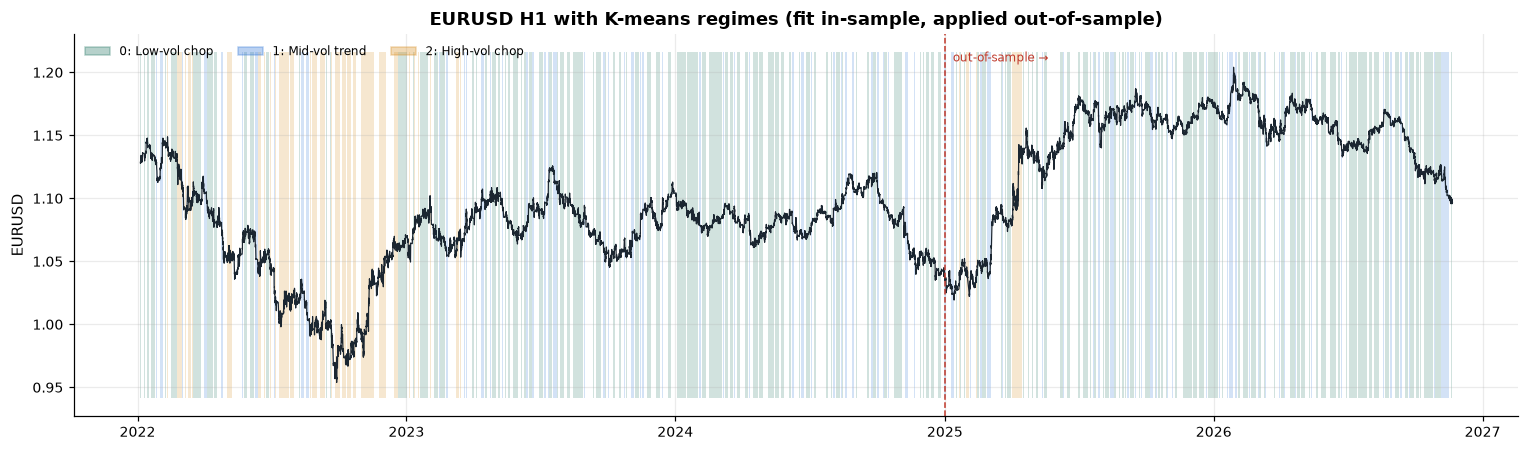

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(features.index, prices.loc[features.index, "close"], color="#1B2631", lw=0.8, zorder=2)
ax.set_ylabel("EURUSD")
ax.set_title("EURUSD H1 with K-means regimes (fit in-sample, applied out-of-sample)")
split_x = mdates.date2num(IS_END.tz_convert("UTC").tz_localize(None).to_pydatetime())
ax.axvline(split_x, color="#C0392B", ls="--", lw=1)
ax.text(split_x, ax.get_ylim()[1], "  out-of-sample →", va="top", fontsize=8, color="#C0392B")

# daily shading: hourly labels would alias into a barcode at this width
km_daily = pd.Series(KM_LABELS, index=features.index).resample("1D").last().dropna()
paint_regimes(ax, km_daily.index, km_daily.values, colors=REGIME_COLORS, alpha=0.22)
handles = [plt.Rectangle((0, 0), 1, 1, color=REGIME_COLORS[i], alpha=0.35, label=f"{i}: {KM_NAMES[i]}")
           for i in range(K_REGIMES)]
ax.legend(handles=handles, loc="upper left", ncol=K_REGIMES, fontsize=8)
savefig(fig, "03_kmeans_timeline")
plt.show()

### 3.4 Transition matrix and persistence

A regime that lasts one bar is noise, not a regime. The transition matrix answers
`P(state_t = j | state_{t−1} = i)`; its diagonal is persistence, and expected duration is
`1 / (1 − P(stay))` bars.

> A useful rule of thumb: if the average duration is shorter than the horizon over which your
> strategy rebalances, the regime label is not actionable.

,to Low-vol chop,to Mid-vol trend,to High-vol chop
from Low-vol chop,95.400,3.700,0.900
from Mid-vol trend,7.300,91.600,1.200
from High-vol chop,3.400,2.600,94.000


expected duration (bars): [21.9 11.9 16.5]
expected duration (days): [0.9 0.5 0.7]


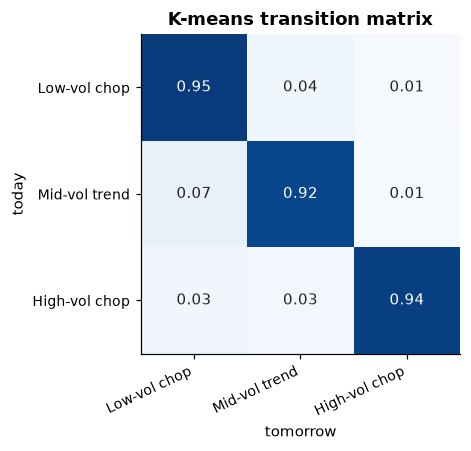

In [12]:
tm = pd.DataFrame(transition_matrix(KM_LABELS, K_REGIMES),
                  index=[f"from {n}" for n in KM_NAMES],
                  columns=[f"to {n}" for n in KM_NAMES])
display((tm * 100).round(1))

print("expected duration (bars):",
      np.round(1 / np.maximum(1e-9, 1 - np.diag(tm.values)), 1))
print("expected duration (days):",
      np.round(1 / np.maximum(1e-9, 1 - np.diag(tm.values)) / 24, 1))

fig, ax = plt.subplots(figsize=(5.4, 4.2))
im = ax.imshow(tm.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K_REGIMES), KM_NAMES, rotation=25, ha="right")
ax.set_yticks(range(K_REGIMES), KM_NAMES)
for i in range(K_REGIMES):
    for j in range(K_REGIMES):
        ax.text(j, i, f"{tm.values[i, j]:.2f}", ha="center", va="center",
                color="white" if tm.values[i, j] > 0.55 else "#222")
ax.set_title("K-means transition matrix")
ax.set_xlabel("tomorrow"); ax.set_ylabel("today")
ax.grid(False)
savefig(fig, "03_kmeans_transition")
plt.show()

### 3.5 Stability — the test K-means usually fails

If the clusters are real, they should survive (a) a different random seed and (b) a bootstrap
sample of the data. We measure agreement with the **Adjusted Rand Index (ARI)**: 1 = identical
partitioning, 0 = chance.

* ARI > 0.8 → very stable.
* ARI 0.5–0.8 → usable but noisy.
* ARI < 0.5 → the "regimes" are mostly arbitrary; do not build a strategy on them.

seed ARI     mean=0.999  min=0.999
bootstrap ARI mean=0.987  min=0.971


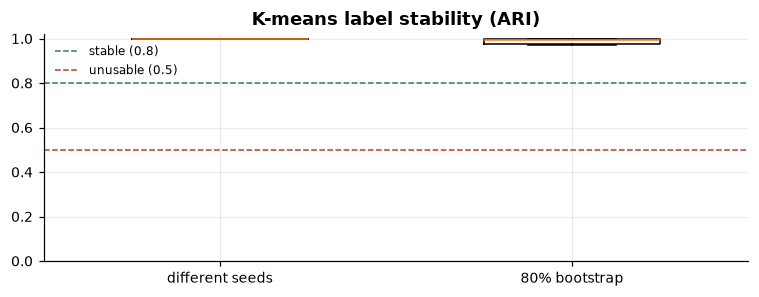

In [13]:
def kmeans_stability(X: np.ndarray, k: int, seed: int = 0, n_seeds: int = 8,
                     n_boot: int = 8, frac: float = 0.8) -> dict:
    base = fit_kmeans(X, k, seed=seed).labels_
    seed_scores = []
    for s in range(n_seeds):
        lab = fit_kmeans(X, k, seed=1000 + s).labels_
        seed_scores.append(adjusted_rand_score(base, lab))
    rng = np.random.default_rng(seed)
    boot_scores = []
    for b in range(n_boot):
        idx = rng.choice(len(X), size=int(frac * len(X)), replace=False)
        km = fit_kmeans(X[idx], k, seed=2000 + b)
        boot_scores.append(adjusted_rand_score(base, km.predict(X)))
    return {"seed_ari": np.array(seed_scores), "boot_ari": np.array(boot_scores)}


stab = kmeans_stability(X_is, K_REGIMES, seed=CONFIG["seed"])
print(f"seed ARI     mean={stab['seed_ari'].mean():.3f}  min={stab['seed_ari'].min():.3f}")
print(f"bootstrap ARI mean={stab['boot_ari'].mean():.3f}  min={stab['boot_ari'].min():.3f}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.boxplot([stab["seed_ari"], stab["boot_ari"]], tick_labels=["different seeds", "80% bootstrap"],
           widths=0.5)
ax.axhline(0.8, color="#2E7D6B", ls="--", lw=1, label="stable (0.8)")
ax.axhline(0.5, color="#C0392B", ls="--", lw=1, label="unusable (0.5)")
ax.set_ylim(0, 1.02)
ax.set_title("K-means label stability (ARI)")
ax.legend(fontsize=8)
savefig(fig, "03_kmeans_stability")
plt.show()

K-means has now given us a usable first lens. Its blind spot is structural: it treats every bar
as an independent draw, so it cannot express *"a calm market tends to stay calm"*. That is
exactly what the Hidden Markov Model adds.

> **Try it.** Set `K_REGIMES = 4` in the config cell (Part 0) and re-run Parts 3–4. Does the
> fourth state look like a distinct environment, or a split of an existing one? Then set it
> back to 3.

## 4. Hidden Markov Model — regimes that persist

### The idea

K-means says "this bar looks like state 2". A Hidden Markov Model says something stronger:
*the market is in one of K hidden states; each state emits returns/features from its own
distribution; and the state evolves as a Markov chain.*

Two layers:

* **Hidden layer** — a discrete state $s_t \in \{1,\dots,K\}$ with transition matrix
  $A_{ij} = P(s_t = j \mid s_{t-1} = i)$.
* **Observed layer** — features $x_t$ drawn from a state-specific Gaussian
  $x_t \mid s_t = k \sim \mathcal{N}(\mu_k, \Sigma_k)$ (diagonal $\Sigma$ here).

The parameters are $\theta = \{\pi, A, \mu_k, \Sigma_k\}$. We never observe $s_t$; we infer it.

### Why this is the right tool for regimes

The transition matrix encodes **persistence**. A calm market has a high $A_{kk}$, so the model
*expects* calm to continue unless the data strongly disagree. K-means has no such memory. That
is why HMM regimes look like episodes rather than confetti.

### The three questions we ask of an HMM

1. **Filtering** — $P(s_t \mid x_{1:t})$: what state are we in *now*, given only the past?
   This is the only quantity you may trade on.
2. **Smoothing** — $P(s_t \mid x_{1:T})$: what state were we in, given the whole sample?
   Better for *analysis*, illegal for trading (it uses the future).
3. **Decoding** — $\arg\max_{s_{1:T}} P(s_{1:T} \mid x_{1:T})$ (Viterbi): the single most likely
   path. Also uses the whole sample.

This distinction is the most common source of look-ahead bias in regime research. We will
compute all three and keep them clearly separated.

### 4.1 The algorithm, in four equations

**Emission likelihood** (diagonal Gaussian):

$$\log b_k(x_t) = -\tfrac12\sum_{d=1}^{D}\left[\log(2\pi\sigma_{kd}^2) + \frac{(x_{td}-\mu_{kd})^2}{\sigma_{kd}^2}\right]$$

**Forward pass** (scaled to avoid underflow):

$$\alpha_t(j) = \frac{\big[\sum_i \alpha_{t-1}(i)A_{ij}\big]\,b_j(x_t)}{c_t},
\qquad c_t = \sum_j \big[\cdots\big]$$

The log-likelihood is $\sum_t \log c_t$.

**Backward pass**:

$$\beta_t(i) = \frac{\sum_j A_{ij}\,b_j(x_{t+1})\,\beta_{t+1}(j)}{c_{t+1}}$$

**Baum–Welch M-step**:

$$\hat A_{ij} = \frac{\sum_t \xi_t(i,j)}{\sum_t \gamma_t(i)},\quad
\hat\mu_k = \frac{\sum_t \gamma_t(k)x_t}{\sum_t \gamma_t(k)},\quad
\hat\Sigma_k = \frac{\sum_t \gamma_t(k)(x_t-\hat\mu_k)^2}{\sum_t \gamma_t(k)}$$

with $\gamma_t(k) = \alpha_t(k)\beta_t(k)$ normalised across $k$, and
$\xi_t(i,j) \propto \alpha_t(i)A_{ij}b_j(x_{t+1})\beta_{t+1}(j)$.

EM increases the likelihood monotonically. It can still converge to a *local* optimum, which is
why we run several random restarts and keep the best.

> `hmmlearn` has no wheel for this Python version, so the model below is implemented from
> scratch. That is a feature, not a workaround: every line maps to an equation above.

In [14]:
class GaussianHMM:
    """A diagonal-covariance Gaussian Hidden Markov Model, fitted with Baum-Welch (EM).

    Parameters
    ----------
    n_states : number of hidden regimes
    n_iter   : maximum EM iterations per restart
    tol      : stop when the log-likelihood improves by less than this
    var_floor: minimum variance in standardised units (regularisation)
    sticky   : initial self-transition probability (biases towards persistent states)
    """

    def __init__(self, n_states: int = 3, n_iter: int = 150, tol: float = 1e-5,
                 seed: int = 0, var_floor: float = 0.05, sticky: float = 0.8,
                 trans_smooth: float = 1e-3):
        self.n_states = n_states
        self.n_iter = n_iter
        self.tol = tol
        self.seed = seed
        self.var_floor = var_floor
        self.sticky = sticky
        self.trans_smooth = trans_smooth

    # ------------------------------------------------------------------ #
    # emissions
    # ------------------------------------------------------------------ #
    def _log_emissions(self, X: np.ndarray) -> np.ndarray:
        """log N(x_t | mu_k, diag(var_k)) for every t and k -> shape (T, K)."""
        log_norm = -0.5 * np.sum(np.log(2.0 * np.pi * self.var), axis=1)      # (K,)
        diff = X[:, None, :] - self.mu[None, :, :]                            # (T, K, D)
        return log_norm[None, :] - 0.5 * np.sum(diff ** 2 / self.var[None, :, :], axis=2)

    # ------------------------------------------------------------------ #
    # initialisation
    # ------------------------------------------------------------------ #
    def _init_params(self, X: np.ndarray, rng: np.random.Generator) -> None:
        k = self.n_states
        km = KMeans(n_clusters=k, n_init=5, random_state=int(rng.integers(1_000_000))).fit(X)
        self.mu = np.array([X[km.labels_ == j].mean(0) for j in range(k)])
        self.var = np.array([X[km.labels_ == j].var(0) for j in range(k)]) + self.var_floor
        self.A = np.full((k, k), (1.0 - self.sticky) / max(1, k - 1))
        np.fill_diagonal(self.A, self.sticky)
        self.pi = np.full(k, 1.0 / k)

    # ------------------------------------------------------------------ #
    # forward-backward (scaled)
    # ------------------------------------------------------------------ #
    def _forward_backward(self, X: np.ndarray):
        T = len(X)
        log_b = self._log_emissions(X)
        B = np.exp(np.clip(log_b, -700.0, 0.0))          # (T, K) emission probabilities

        alpha = np.empty((T, self.n_states))
        c = np.empty(T)
        alpha[0] = self.pi * B[0]
        c[0] = alpha[0].sum()
        if c[0] <= 0:
            alpha[0], c[0] = np.full(self.n_states, 1.0 / self.n_states), 1.0
        alpha[0] /= c[0]

        for t in range(1, T):
            alpha[t] = (alpha[t - 1] @ self.A) * B[t]
            c[t] = alpha[t].sum()
            if c[t] <= 0:
                alpha[t], c[t] = np.full(self.n_states, 1.0 / self.n_states), 1.0
            alpha[t] /= c[t]

        beta = np.ones((T, self.n_states))
        for t in range(T - 2, -1, -1):
            beta[t] = (self.A @ (B[t + 1] * beta[t + 1])) / c[t + 1]

        gamma = alpha * beta
        gamma /= gamma.sum(1, keepdims=True) + 1e-300

        # xi[t, i, j] = P(s_t=i, s_{t+1}=j | x_{1:T})
        xi = (alpha[:-1, :, None] * self.A[None, :, :]
              * B[1:, None, :] * beta[1:, None, :]) / c[1:, None, None]

        return float(np.log(c).sum()), gamma, xi

    # ------------------------------------------------------------------ #
    # fitting
    # ------------------------------------------------------------------ #
    def _snapshot(self):
        return dict(pi=self.pi.copy(), A=self.A.copy(), mu=self.mu.copy(), var=self.var.copy())

    def _restore(self, snap):
        self.pi, self.A, self.mu, self.var = snap["pi"], snap["A"], snap["mu"], snap["var"]

    def fit(self, X: np.ndarray, n_restarts: int = 2, verbose: bool = True):
        best_ll, best_snap, best_hist = -np.inf, None, []
        self.histories_ = []

        for restart in range(n_restarts):
            rng = np.random.default_rng(self.seed + restart)
            self._init_params(X, rng)
            prev_ll, hist = -np.inf, []
            for it in range(self.n_iter):
                ll, gamma, xi = self._forward_backward(X)

                # --- M-step -------------------------------------------------
                self.pi = gamma[0] / gamma[0].sum()
                A = xi.sum(0) + self.trans_smooth
                self.A = A / A.sum(1, keepdims=True)
                w = gamma.sum(0) + 1e-10
                self.mu = (gamma[:, :, None] * X[:, None, :]).sum(0) / w[:, None]
                self.var = ((gamma[:, :, None] * (X[:, None, :] - self.mu[None, :, :]) ** 2).sum(0)
                            / w[:, None]) + self.var_floor

                hist.append(ll)
                if ll - prev_ll < self.tol:
                    break
                prev_ll = ll

            self.histories_.append(hist)
            if verbose:
                print(f"  restart {restart}: log-likelihood {ll:,.2f} after {it + 1} iterations")
            if ll > best_ll:
                best_ll, best_snap, best_hist = ll, self._snapshot(), hist

        self._restore(best_snap)
        self.log_likelihood_ = best_ll
        self.history_ = best_hist
        self.n_iter_ = len(best_hist)
        self.n_params_ = (self.n_states - 1) + self.n_states * (self.n_states - 1) \
                         + 2 * self.n_states * X.shape[1]
        return self

    # ------------------------------------------------------------------ #
    # inference
    # ------------------------------------------------------------------ #
    def viterbi(self, X: np.ndarray) -> np.ndarray:
        """Most likely state path given the WHOLE sequence (uses the future)."""
        T = len(X)
        log_b = self._log_emissions(X)
        delta = np.empty((T, self.n_states))
        psi = np.zeros((T, self.n_states), dtype=int)
        delta[0] = np.log(self.pi + 1e-300) + log_b[0]
        log_A = np.log(self.A + 1e-300)
        for t in range(1, T):
            scores = delta[t - 1][:, None] + log_A
            psi[t] = scores.argmax(0)
            delta[t] = scores.max(0) + log_b[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

    def filter_proba(self, X: np.ndarray) -> np.ndarray:
        """P(state_t | x_{1:t}) -- causal, the only version safe for trading."""
        T = len(X)
        B = np.exp(np.clip(self._log_emissions(X), -700.0, 0.0))
        out = np.empty((T, self.n_states))
        out[0] = self.pi * B[0]
        s = out[0].sum()
        out[0] = out[0] / s if s > 0 else np.full(self.n_states, 1.0 / self.n_states)
        for t in range(1, T):
            out[t] = (out[t - 1] @ self.A) * B[t]
            s = out[t].sum()
            out[t] = out[t] / s if s > 0 else np.full(self.n_states, 1.0 / self.n_states)
        return out

    def smooth_proba(self, X: np.ndarray) -> np.ndarray:
        """P(state_t | x_{1:T}) -- uses the future, for analysis only."""
        return self._forward_backward(X)[1]

    # ------------------------------------------------------------------ #
    # model selection and utilities
    # ------------------------------------------------------------------ #
    def bic(self, X: np.ndarray, log_likelihood: float | None = None) -> float:
        ll = self.log_likelihood_ if log_likelihood is None else log_likelihood
        return -2.0 * ll + self.n_params_ * np.log(len(X))

    def aic(self, X: np.ndarray, log_likelihood: float | None = None) -> float:
        ll = self.log_likelihood_ if log_likelihood is None else log_likelihood
        return -2.0 * ll + 2.0 * self.n_params_

    def stationary_distribution(self) -> np.ndarray:
        """Long-run share of each state: the eigenvector of A' for eigenvalue 1."""
        vals, vecs = np.linalg.eig(self.A.T)
        v = np.real(vecs[:, np.argmin(np.abs(vals - 1.0))])
        v = np.abs(v)
        return v / v.sum()

    def permute(self, order: np.ndarray):
        """Relabel states so that order[new] = old (used to sort by volatility)."""
        order = np.asarray(order, dtype=int)
        self.pi = self.pi[order]
        self.A = self.A[np.ix_(order, order)]
        self.mu = self.mu[order]
        self.var = self.var[order]
        return self

    def expected_durations(self) -> np.ndarray:
        return 1.0 / np.maximum(1e-9, 1.0 - np.diag(self.A))

### 4.2 Fit on the in-sample period

Three practical choices, all of which you should experiment with:

* **`sticky=0.8`** — the initial self-transition probability. Higher values bias towards
  slower regimes; EM can move away from it, but it rarely moves far.
* **`var_floor=0.05`** — a floor on the emission variance in standardised units. Without it, a
  state can collapse onto a handful of outliers and declare them a "regime".
* **`n_restarts=2`** — EM finds local optima. Running twice and keeping the better likelihood is
  cheap insurance.

The convergence plot should rise and flatten. A jagged or declining curve means a bug in the
update equations, not "market noise".

  restart 0: log-likelihood -101,917.14 after 68 iterations


  restart 1: log-likelihood -101,917.14 after 68 iterations


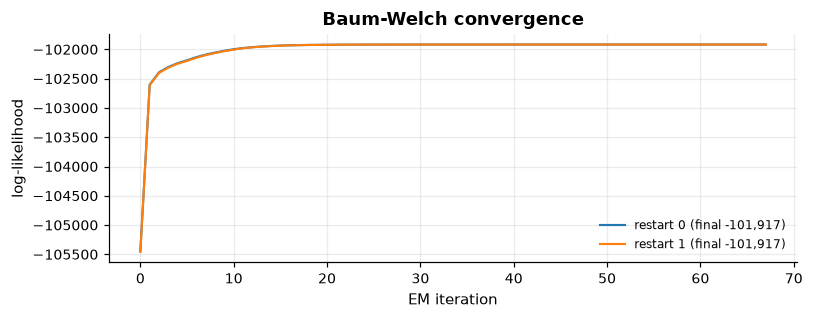

best log-likelihood: -101,917.14
parameters: 38   BIC: 204,207.9   AIC: 203,910.3


In [15]:
hmm = GaussianHMM(
    n_states=K_REGIMES,
    n_iter=150,
    tol=1e-5,
    seed=CONFIG["seed"],
    var_floor=0.05,
    sticky=0.8,
).fit(X_is, n_restarts=2)

fig, ax = plt.subplots(figsize=(7.5, 3.0))
for i, hist in enumerate(hmm.histories_):
    ax.plot(hist, lw=1.4, label=f"restart {i} (final {hist[-1]:,.0f})")
ax.set(title="Baum-Welch convergence", xlabel="EM iteration", ylabel="log-likelihood")
ax.legend(fontsize=8)
savefig(fig, "04_hmm_convergence")
plt.show()

print(f"best log-likelihood: {hmm.log_likelihood_:,.2f}")
print(f"parameters: {hmm.n_params_}   BIC: {hmm.bic(X_is):,.1f}   AIC: {hmm.aic(X_is):,.1f}")

### 4.3 What did it learn?

The emission means are in **standardised** units, so we inverse-transform them before reading.
We then relabel states by volatility so `0` is always the calmest state — otherwise a re-run
could silently swap the names.

In [16]:
# sort states by average volatility (feature 0) so the labels are stable across runs
vol_idx = FEATURES.index("vol_24")
order = np.argsort(hmm.mu[:, vol_idx])
hmm.permute(order)

HMM_NAMES = name_regimes(
    pd.DataFrame(scaler.inverse_transform(hmm.mu), columns=FEATURES)
)

state_table = pd.DataFrame(scaler.inverse_transform(hmm.mu), columns=FEATURES)
state_table.insert(0, "name", HMM_NAMES)
state_table["stationary share"] = hmm.stationary_distribution()
state_table["expected duration (bars)"] = hmm.expected_durations()
state_table["expected duration (days)"] = state_table["expected duration (bars)"] / 24.0
display(state_table.round(3))

A_df = pd.DataFrame(hmm.A, index=[f"from {n}" for n in HMM_NAMES],
                    columns=[f"to {n}" for n in HMM_NAMES])
display((A_df * 100).round(1))

,name,vol_24,atr_pct,adx_14,trend_r2_48,er_24,stationary share,expected duration (bars),expected duration (days)
0,Low-vol chop,0.058,0.111,19.107,0.314,0.153,0.464,39.756,1.657
1,Mid-vol trend,0.065,0.117,36.387,0.637,0.344,0.304,26.322,1.097
2,High-vol chop,0.123,0.210,27.901,0.409,0.226,0.232,45.647,1.902


,to Low-vol chop,to Mid-vol trend,to High-vol chop
from Low-vol chop,97.500,1.900,0.600
from Mid-vol trend,3.100,96.200,0.700
from High-vol chop,1.000,1.200,97.800


Two sanity checks:

* **Persistence.** The diagonal of $A$ should be high (0.9+). If not, the model is flickering
  between states and the "regimes" are not regimes.
* **Stationary shares.** The long-run share implied by $A$ should roughly match the observed
  share of each state. A large mismatch means the chain is poorly identified.

### 4.4 Filtered vs smoothed vs Viterbi — see the difference

The top panel shades the price by the **filtered** state (what you would know in real time).
The middle panel shows the filtered probability of each state; the bottom panel compares the
filtered path with the **Viterbi** path (which sees the whole sample). Where they disagree, the
Viterbi path is using information you did not have.

filtered vs Viterbi agreement: 93.1%
bars with filtered confidence > 0.90: 90.8%
bars with filtered confidence < 0.60: 1.7%


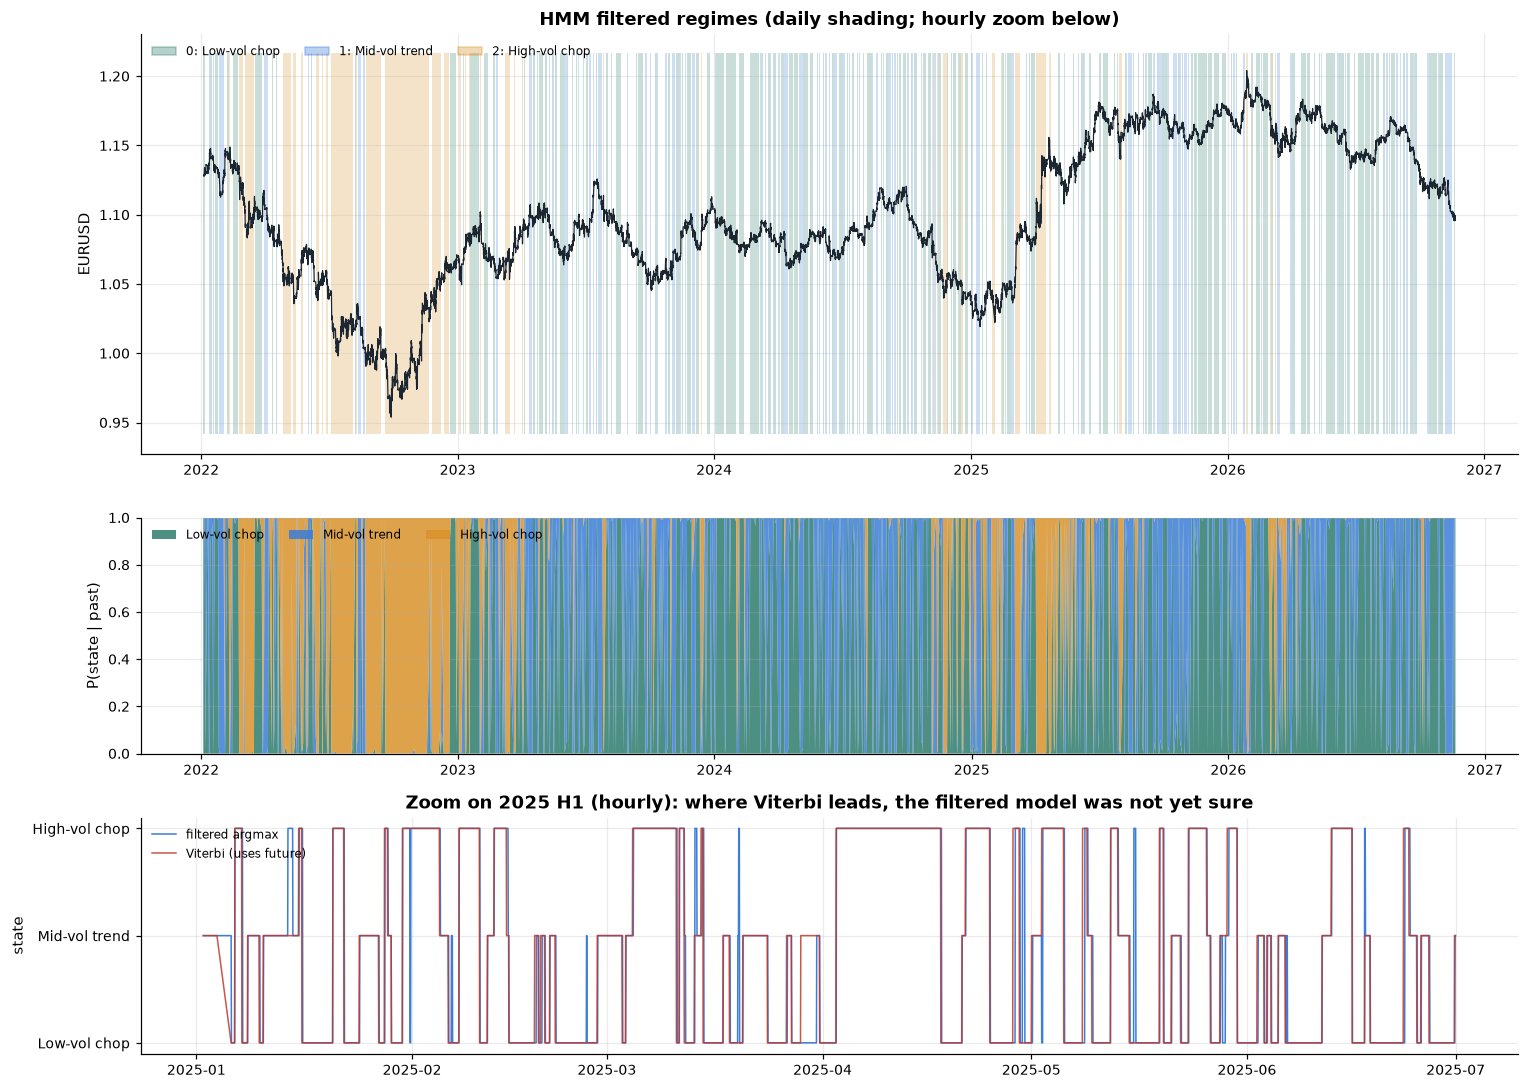

In [17]:
HMM_FILTER = hmm.filter_proba(Z_full)          # (T, K) causal probabilities
HMM_SMOOTH = hmm.smooth_proba(Z_full)          # (T, K) full-sample posterior
HMM_VITERBI = hmm.viterbi(Z_full)              # (T,) most likely path

HMM_LABELS = HMM_FILTER.argmax(1)              # what we would trade on
HMM_CONF = HMM_FILTER.max(1)

print(f"filtered vs Viterbi agreement: {(HMM_LABELS == HMM_VITERBI).mean():.1%}")
print(f"bars with filtered confidence > 0.90: {(HMM_CONF > 0.9).mean():.1%}")
print(f"bars with filtered confidence < 0.60: {(HMM_CONF < 0.6).mean():.1%}")

fig, axes = plt.subplots(3, 1, figsize=(14, 10),
                         gridspec_kw={"height_ratios": [1.6, 0.9, 0.9]})
daily_lab = pd.Series(HMM_LABELS, index=features.index).resample("1D").last().dropna()
daily_prob = (pd.DataFrame(HMM_FILTER, index=features.index, columns=HMM_NAMES)
              .resample("1D").last().dropna())

ax = axes[0]
ax.plot(features.index, prices.loc[features.index, "close"], color="#1B2631", lw=0.8, zorder=2)
ax.set_ylabel("EURUSD")
ax.set_title("HMM filtered regimes (daily shading; hourly zoom below)")
paint_regimes(ax, daily_lab.index, daily_lab.values, alpha=0.25)
handles = [plt.Rectangle((0, 0), 1, 1, color=REGIME_COLORS[i], alpha=0.35, label=f"{i}: {HMM_NAMES[i]}")
           for i in range(K_REGIMES)]
ax.legend(handles=handles, loc="upper left", ncol=K_REGIMES, fontsize=8)

ax = axes[1]
ax.stackplot(daily_prob.index, daily_prob.T.values, colors=REGIME_COLORS[:K_REGIMES],
             labels=HMM_NAMES, alpha=0.85, linewidth=0)
ax.set_ylim(0, 1)
ax.set_ylabel("P(state | past)")
ax.legend(loc="upper left", ncol=K_REGIMES, fontsize=8)

ax = axes[2]
zoom = (features.index >= pd.Timestamp("2025-01-01", tz="UTC")) & \
       (features.index < pd.Timestamp("2025-07-01", tz="UTC"))
ax.plot(features.index[zoom], HMM_LABELS[zoom], lw=1.0, color="#3B7DD8", label="filtered argmax")
ax.plot(features.index[zoom], HMM_VITERBI[zoom], lw=1.0, color="#C0392B", alpha=0.85,
        label="Viterbi (uses future)")
ax.set_yticks(range(K_REGIMES), HMM_NAMES)
ax.set_ylabel("state")
ax.set_title("Zoom on 2025 H1 (hourly): where Viterbi leads, the filtered model was not yet sure")
ax.legend(loc="upper left", fontsize=8)
savefig(fig, "04_hmm_timeline")
plt.show()

**Time scale matters.** At hourly frequency these states last 1–2 days; at five-year scale the
shading looks like a barcode. That is not a bug — it is what an hour-level volatility state looks
like. If you want weeks-long "market environments", compute the features on daily bars or impose
a much stronger persistence prior. Because Part 8 rebalances daily, a 1–2 day regime is right at
the edge of being actionable; a monthly allocator would need slower states.

Where the red line leads the blue line, Viterbi "knew" a regime was ending before the filtered
model did. That is exactly the information a live trader would not have. Any backtest that
switches on Viterbi labels is cheating by a few hours to a few days per transition — enough to
manufacture a fake edge.

### 4.5 Choosing the number of states

More states always improve the in-sample likelihood (more parameters). We penalise that with
**BIC**:

$$\mathrm{BIC} = -2\log L + p\ln T,\qquad p = (K-1) + K(K-1) + 2KD$$

Fit K = 2…5 on a subsample (for speed) and look at the curve. A minimum is evidence for that K;
a monotone decline means the penalty is not doing the work — then choose on stability and
interpretability instead.

,log_likelihood,BIC,AIC,iters
K,,,,
2,"-37,992.800","76,186.500","76,031.600",31
3,"-34,903.000","70,137.900","69,882.000",48
4,"-33,435.100","67,350.600","66,980.200",14
5,"-32,010.700","64,667.700","64,169.400",21


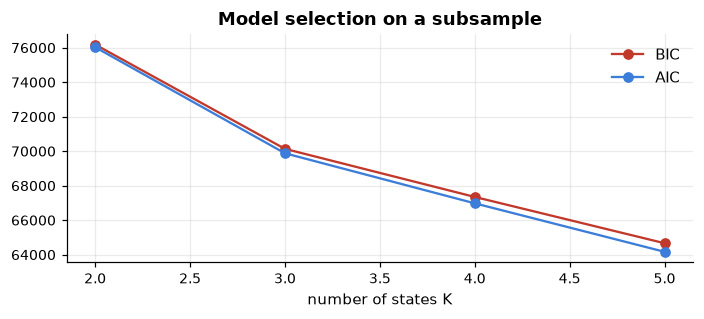

In [18]:
def select_states(X: np.ndarray, ks=range(2, 6), step: int = 3, seed: int = 0) -> pd.DataFrame:
    """Approximate BIC/AIC sweep on a subsample (full EM for every K is slow)."""
    Xs = X[::step]
    rows = []
    for k in ks:
        model = GaussianHMM(n_states=k, n_iter=60, seed=seed, var_floor=0.05, sticky=0.8)
        model.fit(Xs, n_restarts=1, verbose=False)
        rows.append({"K": k, "log_likelihood": model.log_likelihood_,
                     "BIC": model.bic(Xs), "AIC": model.aic(Xs),
                     "iters": model.n_iter_})
    return pd.DataFrame(rows).set_index("K")


bic_table = select_states(X_is, ks=range(2, 6), step=3, seed=CONFIG["seed"])
display(bic_table.round(1))

fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.plot(bic_table.index, bic_table["BIC"], "o-", color="#C0392B", label="BIC")
ax.plot(bic_table.index, bic_table["AIC"], "o-", color="#3B7DD8", label="AIC")
ax.set(title="Model selection on a subsample", xlabel="number of states K")
ax.legend()
savefig(fig, "04_hmm_bic")
plt.show()

BIC usually punishes complexity, but it is not a truth machine. In this run it **keeps falling**
from K = 2 to K = 5: the likelihood gain from extra states outweighs the penalty. That does not
mean five states are better — it means the penalty is too weak to encode "this state is
economically redundant".

The decision rule I actually use:

1. Does the state have a distinct, stable description (volatility level, trend character)?
2. Does it recur out of sample, or does it exist only in one period?
3. Does adding it improve anything you care about (risk forecast, allocation, drawdown)?

If BIC has no minimum in the range, say so and choose on stability and interpretability. For
this dataset, K = 3 gives calm, trending and high-volatility states, and K = 4 mostly splits the
calm state in two. We keep K = 3.

### 4.6 K-means vs HMM — do they agree?

They should not agree perfectly: K-means partitions feature space, the HMM partitions *time
paths*. The comparison is informative:

* High ARI → both models see the same structure (reassuring).
* Low ARI → the temporal model is adding something K-means cannot see.
* Duration tables show which model produces more persistent episodes.

In [19]:
comparison = pd.DataFrame({
    "regime": range(K_REGIMES),
    "HMM name": HMM_NAMES,
    "K-means share": [float((KM_LABELS == i).mean()) for i in range(K_REGIMES)],
    "HMM share": [float((HMM_LABELS == i).mean()) for i in range(K_REGIMES)],
    "K-means duration": 1 / np.maximum(1e-9, 1 - np.diag(transition_matrix(KM_LABELS, K_REGIMES))),
    "HMM duration": hmm.expected_durations(),
})
print(f"Adjusted Rand Index (K-means vs HMM filtered): {adjusted_rand_score(KM_LABELS, HMM_LABELS):.3f}")
display(comparison.round(2))

Adjusted Rand Index (K-means vs HMM filtered): 0.639


,regime,HMM name,K-means share,HMM share,K-means duration,HMM duration
0,0,Low-vol chop,0.570,0.490,21.940,39.760
1,1,Mid-vol trend,0.290,0.320,11.850,26.320
2,2,High-vol chop,0.140,0.190,16.540,45.650


**K-means is not obsolete.** It is faster, needs no distributional assumption, and often
produces cleaner *contemporaneous* descriptions. The HMM's advantage is temporal: it tells you
how likely a switch is, and it gives calibrated transition probabilities. In Part 8 we will
test whether that advantage is worth anything in a portfolio.

### HMM pitfalls to remember

| Pitfall | Symptom | Fix |
|---|---|---|
| Local optima | Different seeds → different likelihoods/states | Multiple restarts, keep best |
| Label switching | State 0 becomes state 2 after refit | Sort states by volatility/mean |
| Overfitting K | Great in-sample, meaningless states | BIC + economic interpretability + OOS |
| Non-Gaussian features | States driven by outliers | Robust scaling, variance floor, fatter tails |
| Look-ahead | Using smoothed/Viterbi labels | Use `filter_proba` for anything tradable |
| Regime drift | Parameters fitted in 2022 fail in 2025 | Refit periodically, monitor likelihood |

> **Try it.** Change `n_states` to 4 and `sticky` to 0.95, then re-run 4.2–4.4. Do the extra
> states look like genuinely different environments, or like one state split in two? Does the
> average duration become implausibly long?

## 5. What actually differs between regimes?

A regime label is only useful if the *conditional distribution* of returns differs across
states. This section measures that difference properly, instead of eyeballing the timeline.

We ask four questions:

1. **Location** — is the average return different? (Usually: barely.)
2. **Dispersion** — is volatility different? (Usually: dramatically.)
3. **Shape** — are tails, skew and autocorrelation different? (Often: yes.)
4. **Persistence** — how long does each state last, and how confident is the filter?

> **Statistical vs economic significance.** With ~10,000 bars per regime, a 0.5 bp difference
> in mean return can be "significant" and still be smaller than the spread. Always report the
> effect size next to the p-value.

In [20]:
def regime_profile(returns: np.ndarray, labels: np.ndarray, names: list[str],
                   freq: int = BARS_PER_YEAR) -> pd.DataFrame:
    """Conditional statistics of an asset return series, grouped by regime."""
    rows = []
    for k, name in enumerate(names):
        mask = labels == k
        rr = np.asarray(returns)[mask]
        rr = rr[np.isfinite(rr)]
        if len(rr) < 10:
            continue
        rows.append({
            "regime": k,
            "name": name,
            "share": float(mask.mean()),
            "bars": int(len(rr)),
            "mean (bps/bar)": float(rr.mean() * 1e4),
            "ann. vol": float(rr.std() * np.sqrt(freq)),
            "Sharpe": float(rr.mean() / rr.std() * np.sqrt(freq)) if rr.std() > 0 else np.nan,
            "hit rate": float((rr > 0).mean()),
            "skew": float(stats.skew(rr)),
            "excess kurt": float(stats.kurtosis(rr)),
            "p05 (bps)": float(np.quantile(rr, 0.05) * 1e4),
            "p95 (bps)": float(np.quantile(rr, 0.95) * 1e4),
            "autocorr(1)": float(pd.Series(rr).autocorr(1)),
        })
    return pd.DataFrame(rows).set_index("regime")


r_asset = features["log_ret"].values
profile = regime_profile(r_asset, HMM_LABELS, HMM_NAMES)
display(profile.round(3))

# what defines each state? feature means
fingerprint = pd.DataFrame(index=range(K_REGIMES), columns=FEATURES, dtype=float)
for k in range(K_REGIMES):
    fingerprint.loc[k] = features.loc[HMM_LABELS == k, FEATURES].mean()
fingerprint.insert(0, "name", HMM_NAMES)
print("\nfeature fingerprint:")
display(fingerprint.round(3))

,name,share,bars,mean (bps/bar),ann. vol,Sharpe,hit rate,skew,excess kurt,p05 (bps),p95 (bps),autocorr(1)
regime,,,,,,,,,,,,
0,Low-vol chop,0.495,15040,0.004,0.062,0.039,0.493,-0.193,7.052,-12.026,12.180,-0.041
1,Mid-vol trend,0.316,9595,-0.099,0.066,-0.904,0.486,0.079,8.023,-12.857,12.375,-0.009
2,High-vol chop,0.190,5769,0.105,0.121,0.523,0.495,0.150,10.664,-22.476,23.290,-0.029



feature fingerprint:


,name,vol_24,atr_pct,adx_14,trend_r2_48,er_24
0,Low-vol chop,0.056,0.109,19.228,0.299,0.160
1,Mid-vol trend,0.062,0.115,36.245,0.650,0.324
2,High-vol chop,0.122,0.209,28.171,0.420,0.231


**How to read the profile.** Compare `ann. vol` across rows: if the high-vol state is 2–3× the
calm state, the model has found the volatility dimension — the robust, repeatable part of regime
research. Compare `mean (bps/bar)`: if the differences are tiny relative to `p05`/`p95`, the
regimes do **not** predict direction. That is normal, and it is the single most important thing
to internalise before building a "regime timing" strategy.

### 5.1 Is the difference real? Welch t-test and Mann–Whitney

For each regime we test its returns against all other bars:

* **Welch t-test** — difference in means, unequal variances.
* **Mann–Whitney U** — difference in distributions, no normality assumption.

With K tests we also report a Bonferroni-adjusted threshold ($\alpha/K$). Remember that both
tests assume independent observations; hourly returns are not, so p-values are optimistic. Use
them as a filter, not as proof.

,name,mean diff (bps),t-stat,p (Welch),p (Mann-Whitney),p x K (Bonferroni),significant at 5%?
regime,,,,,,,
0,Low-vol chop,0.027,0.232,0.817,0.507,1.000,no
1,Mid-vol trend,-0.131,-1.149,0.251,0.377,0.752,no
2,High-vol chop,0.141,0.665,0.506,0.839,1.000,no


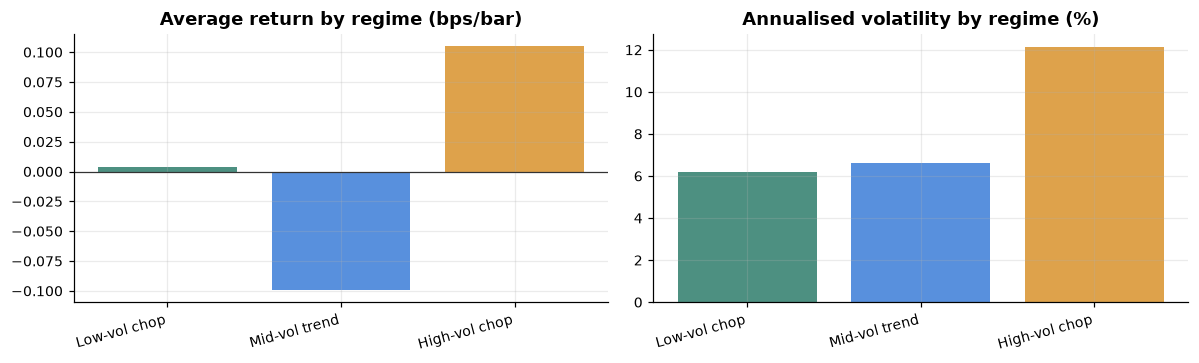

In [21]:
tests = []
for k, name in enumerate(HMM_NAMES):
    a = r_asset[HMM_LABELS == k]
    b = r_asset[HMM_LABELS != k]
    t, p_t = stats.ttest_ind(a, b, equal_var=False)
    u, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    tests.append({
        "regime": k,
        "name": name,
        "mean diff (bps)": (a.mean() - b.mean()) * 1e4,
        "t-stat": t,
        "p (Welch)": p_t,
        "p (Mann-Whitney)": p_u,
        "p x K (Bonferroni)": min(1.0, p_t * K_REGIMES),
        "significant at 5%?": "yes" if p_t * K_REGIMES < 0.05 else "no",
    })
tests = pd.DataFrame(tests).set_index("regime")
display(tests.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(range(K_REGIMES), profile["mean (bps/bar)"], color=REGIME_COLORS[:K_REGIMES], alpha=0.85)
axes[0].axhline(0, color="#333", lw=0.8)
axes[0].set_xticks(range(K_REGIMES), HMM_NAMES, rotation=15, ha="right")
axes[0].set_title("Average return by regime (bps/bar)")

axes[1].bar(range(K_REGIMES), profile["ann. vol"] * 100, color=REGIME_COLORS[:K_REGIMES], alpha=0.85)
axes[1].set_xticks(range(K_REGIMES), HMM_NAMES, rotation=15, ha="right")
axes[1].set_title("Annualised volatility by regime (%)")
savefig(fig, "05_regime_profile_bars")
plt.show()

### 5.2 Return distributions by regime

Averages hide the shape. The box/violin plot shows the full conditional distribution (clipped
at the 1st/99th percentile so the outliers do not swallow the plot). Look for:

* **Different widths** → volatility regimes are real.
* **Different tails** → crisis states have fat left tails.
* **Different medians** → rare; if absent, direction is not regime-dependent.

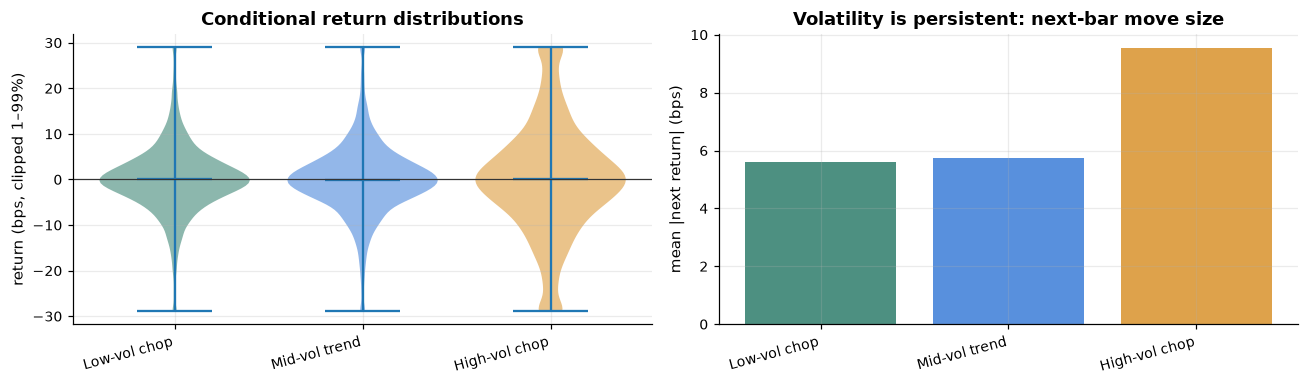

In [22]:
clip = np.quantile(r_asset, [0.01, 0.99])
data = [np.clip(r_asset[HMM_LABELS == k] * 1e4, clip[0] * 1e4, clip[1] * 1e4)
        for k in range(K_REGIMES)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
parts = axes[0].violinplot(data, showmedians=True, widths=0.8)
for i, body in enumerate(parts["bodies"]):
    body.set_facecolor(REGIME_COLORS[i])
    body.set_alpha(0.55)
axes[0].set_xticks(range(1, K_REGIMES + 1), HMM_NAMES, rotation=15, ha="right")
axes[0].set_ylabel("return (bps, clipped 1–99%)")
axes[0].set_title("Conditional return distributions")
axes[0].axhline(0, color="#333", lw=0.8)

# volatility persistence: |return| in the NEXT bar, by current regime
next_abs = np.r_[np.abs(r_asset[1:]), np.nan]
by_regime = [np.nanmean(next_abs[HMM_LABELS == k]) * 1e4 for k in range(K_REGIMES)]
axes[1].bar(range(K_REGIMES), by_regime, color=REGIME_COLORS[:K_REGIMES], alpha=0.85)
axes[1].set_xticks(range(K_REGIMES), HMM_NAMES, rotation=15, ha="right")
axes[1].set_ylabel("mean |next return| (bps)")
axes[1].set_title("Volatility is persistent: next-bar move size")
savefig(fig, "05_regime_distributions")
plt.show()

### 5.3 Momentum or mean reversion, by regime?

Regime research often claims "trends work in trending markets, mean reversion works in choppy
ones". You can test that directly: compute the autocorrelation of returns *within* each regime.

* Positive autocorrelation → moves tend to continue (momentum).
* Negative autocorrelation → moves tend to reverse (mean reversion).

The caveat: subsetting a time series by regime destroys contiguity, so these are indicative, not
exact. A cleaner test is in Part 7, where actual strategy P&L is conditioned on regime.

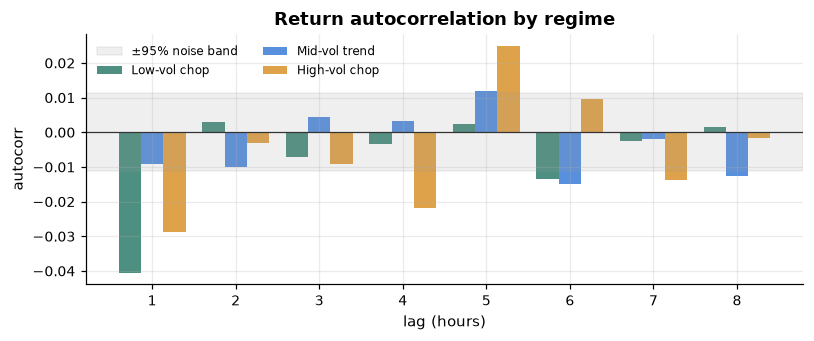

In [23]:
lags = range(1, 9)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
width = 0.8 / K_REGIMES
for k in range(K_REGIMES):
    vals = [pd.Series(r_asset[HMM_LABELS == k]).autocorr(lag) for lag in lags]
    ax.bar(np.array(list(lags)) + (k - (K_REGIMES - 1) / 2) * width, vals, width=width,
           color=REGIME_COLORS[k], alpha=0.85, label=HMM_NAMES[k])
ax.axhline(0, color="#333", lw=0.8)
ci = 1.96 / np.sqrt(len(r_asset))
ax.axhspan(-ci, ci, color="#999", alpha=0.15, label="±95% noise band")
ax.set(title="Return autocorrelation by regime", xlabel="lag (hours)", ylabel="autocorr")
ax.legend(fontsize=8, ncol=2)
savefig(fig, "05_regime_autocorr")
plt.show()

### 5.4 Duration and stability over time

Two checks that separate a real regime model from a data-snooping artefact:

1. **Duration distribution** — should look like a survival curve, not a spike at 1 bar.
2. **Regime share over time** — if one state only exists in 2022, the model learned a period,
   not a regime. Compare in-sample and out-of-sample shares.

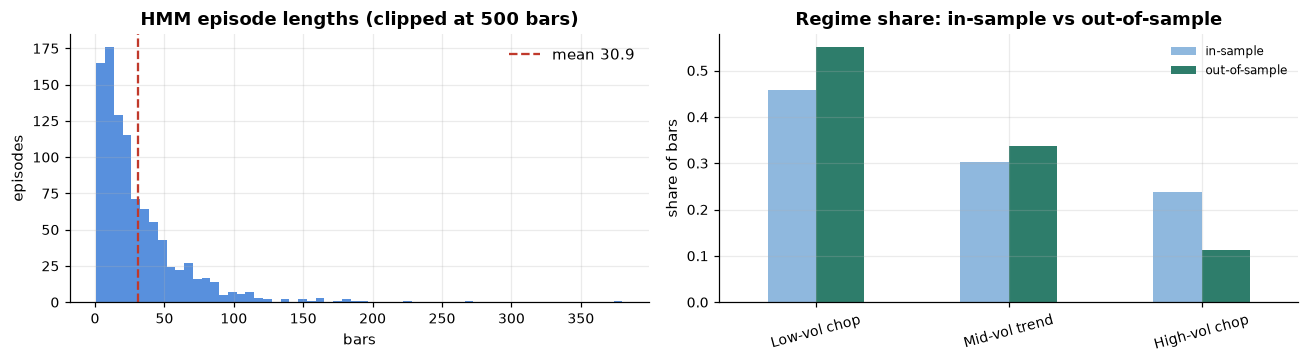

               in-sample  out-of-sample
Low-vol chop       0.459          0.551
Mid-vol trend      0.303          0.336
High-vol chop      0.238          0.113

mean episode: 30.9 bars (1.3 days) | median: 21 bars


In [24]:
runs = run_lengths(HMM_LABELS)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(np.clip(runs, 0, 500), bins=60, color="#3B7DD8", alpha=0.85)
axes[0].set(title="HMM episode lengths (clipped at 500 bars)", xlabel="bars", ylabel="episodes")
axes[0].axvline(runs.mean(), color="#C0392B", ls="--", label=f"mean {runs.mean():.1f}")
axes[0].legend()

shares = pd.DataFrame({
    "in-sample": [(HMM_LABELS[is_mask] == k).mean() for k in range(K_REGIMES)],
    "out-of-sample": [(HMM_LABELS[oos_mask] == k).mean() for k in range(K_REGIMES)],
}, index=HMM_NAMES)
shares.plot.bar(ax=axes[1], color=["#8FB8DE", "#2E7D6B"], rot=15)
axes[1].set(title="Regime share: in-sample vs out-of-sample", ylabel="share of bars")
axes[1].legend(fontsize=8)
savefig(fig, "05_regime_durations_shares")
plt.show()

print(shares.round(3))
print(f"\nmean episode: {runs.mean():.1f} bars ({runs.mean()/24:.1f} days) | median: {np.median(runs):.0f} bars")

If the out-of-sample shares are wildly different from the in-sample shares, treat the model as
**unstable** and stop. A regime model that only describes the past is a history essay, not a
signal.

> **Try it.** Change the HMM to `n_states=2` and re-run Part 5. Does the two-state model still
> separate volatility? What happens to the duration distribution?

## 6. The strategy book — your MT5 strategies, reconstructed

### Where the data comes from

`data/strategies_EURUSD_H1.csv` is the **deal history** of 12 strategies from your MT5
backtester:

* Batch **#192**, `m1_ohlc` model, 2022-01-01 → 2026-11-21, 100,000 USD deposit.
* All EURUSD H1, selected from 2,404 completed runs with a greedy max-min filter on
  **realised daily P&L** (max pairwise correlation ≈ 0.47 on that measure). Mark-to-market
  correlation, computed below, turns out to be higher — the gap is itself a lesson: closed-trade
  P&L hides the risk the strategies share while positions are open.
* Each row is one **deal**: `in` opens a position, `out` closes it; `profit`, `commission` and
  `swap` are already netted by MT5.

### Why not just plot `balance`?

MT5's `balance` only moves when a trade **closes**. A strategy can be 5% underwater for weeks
and the balance curve is flat — no risk, no drawdown, no correlation with the market. For
portfolio work we need **mark-to-market equity**:

$$\text{equity}_t = \text{cash}_t + \sum_{\text{open longs}} q\,(P_t - \bar P_{\text{entry}})
+ \sum_{\text{open shorts}} q\,(\bar P_{\text{entry}} - P_t)$$

where `cash` is the last known balance and the sums are marked at the bar close. This is exactly
what the broker shows as *equity* while positions are open.

### Bias warning (read this twice)

These 12 strategies are **survivors of a 7,279-strategy search**. Their backtest Sharpe is
upward-biased by construction, and they share one symbol and one edge family. Any allocation
result in Part 8 inherits that bias. The *method* is what we are learning here; the *number* is
not an expected live return.

In [25]:
STRAT_FILE = DATA / "strategies_EURUSD_H1.csv"
META_FILE = DATA / "strategies_meta.csv"
DEPOSIT = 100_000.0
CONTRACT = 100_000.0  # EURUSD: 1 lot = 100,000 EUR, P&L in USD


def deals_to_equity(deals: pd.DataFrame, close: pd.Series,
                    deposit: float = DEPOSIT, contract: float = CONTRACT) -> pd.DataFrame:
    """Rebuild a mark-to-market equity curve from a deal list.

    Positions are tracked per side (hedging account). Closing deals reduce the average cost
    proportionally; cash is taken from MT5's own `balance` column, so commissions and swaps
    are included exactly as the tester charged them.
    """
    d = deals.sort_values(["deal_time", "seq"]).reset_index(drop=True)
    bar = np.searchsorted(close.index.values, d["deal_time"].values, side="right") - 1
    bar = np.clip(bar, 0, len(close) - 1)

    cash = deposit
    long_lots = short_lots = 0.0
    long_cost = short_cost = 0.0
    segments = []

    for b, row in zip(bar, d.itertuples()):
        vol, price = float(row.volume), float(row.price)
        cash = float(row.balance)
        if row.direction == "in":
            if row.type == "buy":
                long_lots += vol
                long_cost += vol * price
            else:
                short_lots += vol
                short_cost += vol * price
        else:  # closing deal
            if row.type == "sell":          # closes a long
                avg = long_cost / long_lots if long_lots > 0 else price
                qty = min(vol, long_lots)
                long_lots -= qty
                long_cost -= qty * avg
            else:                            # closes a short
                avg = short_cost / short_lots if short_lots > 0 else price
                qty = min(vol, short_lots)
                short_lots -= qty
                short_cost -= qty * avg
        segments.append((int(b), long_lots, long_cost, short_lots, short_cost, cash))

    equity = np.full(len(close), np.nan)
    long_series = np.zeros(len(close))
    short_series = np.zeros(len(close))
    px = close.values

    for i, (b, ll, lc, sl, sc, cash_i) in enumerate(segments):
        end = segments[i + 1][0] if i + 1 < len(segments) else len(close)
        end = max(end, b + 1)
        long_avg = lc / ll if ll > 0 else 0.0
        short_avg = sc / sl if sl > 0 else 0.0
        equity[b:end] = (cash_i + ll * contract * (px[b:end] - long_avg)
                         + sl * contract * (short_avg - px[b:end]))
        long_series[b:end] = ll
        short_series[b:end] = sl

    # before the first deal the account is simply the deposit
    if segments:
        first = segments[0][0]
        equity[:first] = deposit

    return pd.DataFrame({"equity": equity, "long_lots": long_series,
                         "short_lots": short_series}, index=close.index)


deals = pd.read_csv(STRAT_FILE, parse_dates=["deal_time"])
meta = pd.read_csv(META_FILE)
STRATS = list(meta["strategy"])

book = {}
checks = []
for name, g in deals.groupby("strategy"):
    curve = deals_to_equity(g, prices["close"])
    book[name] = curve
    final = curve["equity"].iloc[-1]
    target = DEPOSIT + float(meta.loc[meta.strategy == name, "net_profit"].iloc[0])
    checks.append({"strategy": name, "final equity": final, "MT5 net profit": target,
                   "difference": final - target})

checks = pd.DataFrame(checks).set_index("strategy")
print(f"strategies: {len(book)}   deals: {len(deals):,}")
print(f"max |reconstruction error|: {checks['difference'].abs().max():.4f} USD")
display(checks.round(2))

strategies: 12   deals: 7,198
max |reconstruction error|: 0.0000 USD


,final equity,MT5 net profit,difference
strategy,,,
S01,"121,611.210","121,611.210",0.000
S02,"119,450.520","119,450.520",0.000
S03,"117,077.850","117,077.850",0.000
S04,"116,503.650","116,503.650",0.000
S05,"115,693.420","115,693.420",0.000
S06,"118,507.300","118,507.300",0.000
S07,"118,298.320","118,298.320",0.000
S08,"114,484.510","114,484.510",0.000
S09,"114,663.290","114,663.290",-0.000


If the reconstruction error is not ~0, stop and find the bug. A mark-to-market engine that does
not reproduce the tester's final balance to the cent cannot be trusted with anything else. Here
it matches, because cash comes straight from MT5 and only the *floating* part is modelled.

### 6.1 Equity curves and daily returns

Resampling H1 equity to daily (`last` of each trading day) gives the return series used for
allocation. We keep only days that actually traded — weekends would otherwise enter as zero
returns and dilute volatility.

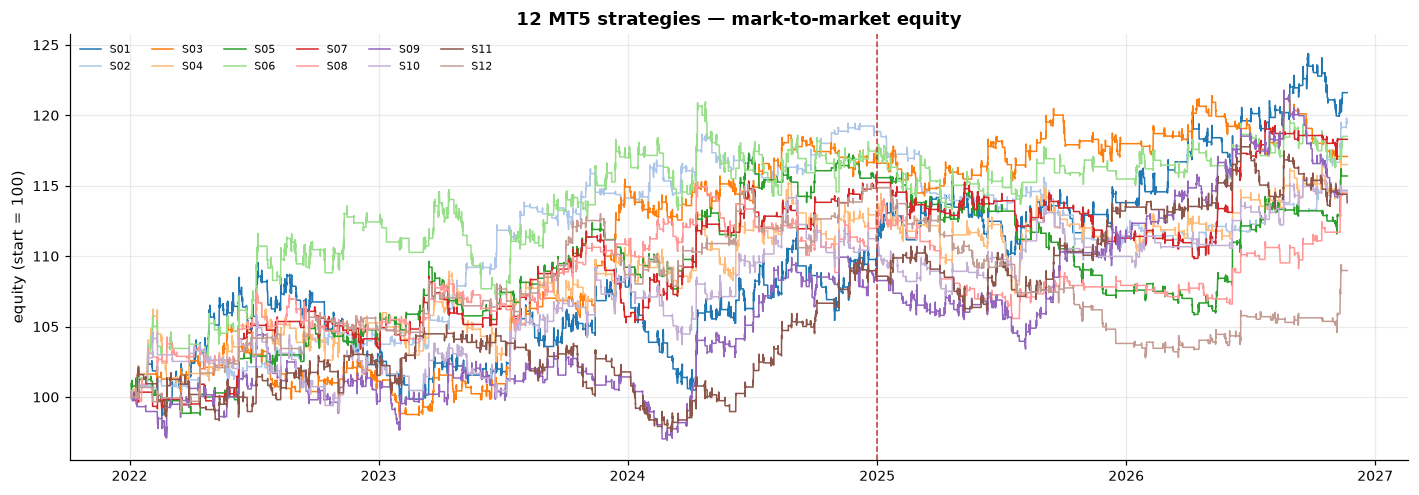

,CAGR,Vol,Sharpe,Sortino,MaxDD,Calmar,HitRate,Bars,exposure,trades
S02,0.036,0.038,0.959,1.037,-0.073,0.490,0.135,"1,267.000",0.122,293
S07,0.034,0.044,0.782,0.916,-0.053,0.642,0.146,"1,267.000",0.148,263
S03,0.032,0.047,0.691,0.950,-0.062,0.511,0.155,"1,267.000",0.155,315
S05,0.028,0.045,0.633,0.843,-0.095,0.293,0.135,"1,267.000",0.142,268
S01,0.040,0.067,0.622,0.849,-0.083,0.482,0.211,"1,267.000",0.265,302
S08,0.027,0.045,0.615,0.690,-0.081,0.334,0.140,"1,267.000",0.103,301
S06,0.035,0.059,0.609,0.850,-0.065,0.533,0.156,"1,267.000",0.175,287
S04,0.031,0.057,0.555,0.710,-0.067,0.460,0.156,"1,267.000",0.148,341
S10,0.027,0.052,0.546,0.631,-0.064,0.430,0.135,"1,267.000",0.115,284
S11,0.026,0.050,0.538,0.735,-0.067,0.387,0.156,"1,267.000",0.169,304


In [26]:
fig, ax = plt.subplots(figsize=(13, 4.6))
cmap = plt.get_cmap("tab20")
for i, name in enumerate(STRATS):
    eq = book[name]["equity"]
    ax.plot(eq.index, eq / DEPOSIT * 100, lw=1.0, color=cmap(i % 20), label=name)
ax.set_ylabel("equity (start = 100)")
ax.set_title("12 MT5 strategies — mark-to-market equity")
ax.axvline(mdates.date2num(IS_END.tz_convert("UTC").tz_localize(None).to_pydatetime()),
           color="#C0392B", ls="--", lw=1)
ax.legend(ncol=6, fontsize=7, loc="upper left")
savefig(fig, "06_strategy_equity")
plt.show()

# daily returns (trading days only)
strat_hourly = pd.DataFrame({name: book[name]["equity"] for name in STRATS})
strat_daily = strat_hourly.resample("1D").last().dropna(how="all")
strat_ret = strat_daily.pct_change(fill_method=None).dropna(how="all")
strat_ret = strat_ret.loc[strat_ret.index >= pd.Timestamp("2022-01-05", tz="UTC")]

exposure = pd.DataFrame({
    name: (book[name][["long_lots", "short_lots"]].abs().sum(axis=1) > 0)
    for name in STRATS
}).resample("1D").mean().reindex(strat_ret.index).fillna(0)

stats = pd.DataFrame({name: perf_stats(strat_ret[name], freq=252, name=name) for name in STRATS}).T
stats["exposure"] = exposure.mean().values
stats["trades"] = [int(meta.loc[meta.strategy == n, "trades"].iloc[0]) for n in STRATS]
display(stats.round(3).sort_values("Sharpe", ascending=False))

**Notice the gap between this table and the MT5 report.** MT5's Sharpe is computed from
*closed-trade* P&L; ours is computed from daily mark-to-market equity. They answer different
questions:

* Closed-trade Sharpe ignores the risk taken while a position is open.
* Mark-to-market Sharpe includes it — and is the correct input for portfolio construction.

This is not a detail. A strategy that holds large positions for weeks can look calm in a
closed-trade report and be the riskiest sleeve in your book.

### 6.2 Correlation structure

Diversification only works if the sleeves are not the same trade in disguise. Twelve variants
from one search on one symbol will be correlated; the question is *how much*.

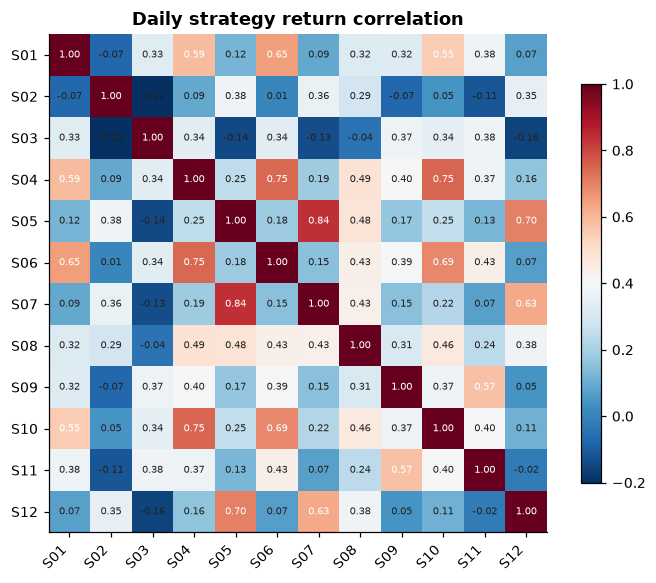

mean pairwise correlation: 0.28   max: 0.84   min: -0.22


In [27]:
corr_s = strat_ret.corr()
fig, ax = plt.subplots(figsize=(6.8, 5.4))
im = ax.imshow(corr_s, cmap="RdBu_r", vmin=-0.2, vmax=1.0)
ax.set_xticks(range(len(STRATS)), STRATS, rotation=45, ha="right")
ax.set_yticks(range(len(STRATS)), STRATS)
for i in range(len(STRATS)):
    for j in range(len(STRATS)):
        ax.text(j, i, f"{corr_s.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=6.5, color="white" if corr_s.iloc[i, j] > 0.55 else "#222")
ax.set_title("Daily strategy return correlation")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
savefig(fig, "06_strategy_correlation")
plt.show()

off = corr_s.values[np.triu_indices_from(corr_s, 1)]
print(f"mean pairwise correlation: {off.mean():.2f}   max: {off.max():.2f}   min: {off.min():.2f}")

A mean pairwise correlation around 0.3 is *workable* — there is genuine diversification — but
it also means the effective number of independent bets is far below 12. A useful shortcut is
the **effective breadth**: $N_{\text{eff}} \approx N / (1 + (N-1)\bar\rho)$. With N=12 and
ρ̄=0.3, that is roughly 3 independent strategies, not 12.

> **Try it.** Compute the correlation of *hourly* returns instead of daily. It will usually be
> lower, because the strategies trade at different times of day. Which frequency is the right
> one for your rebalancing horizon?

## 7. Do strategies behave differently across regimes?

This is the heart of the project. We now have:

* a regime label for every hour (`HMM_LABELS`),
* a mark-to-market return for every strategy and every hour (`strat_h_ret`).

Condition one on the other and you get the **strategy × regime performance matrix**. Three
tables matter:

| Table | Question |
|---|---|
| mean return (bps/hour) | Which strategies *earn* in this regime? |
| Sharpe | Which strategies earn *per unit of risk*? |
| hit rate / exposure | Is the effect real, or is the strategy simply absent? |

### The noise problem (read before interpreting)

Hourly observations are numerous but highly dependent. The annualised Sharpe of a strategy
measured on ~5,000 hourly bars has a standard error of roughly

$$\mathrm{SE}(\widehat{SR}) \approx \sqrt{\frac{1 + SR^2/2}{T}}\sqrt{6048} \approx 1.0$$

That is enormous. A heatmap cell showing Sharpe 1.8 vs 0.6 may be **one standard error apart**.
This is why the table below is a *map of hypotheses*, not a set of conclusions. Part 7.3 attaches
bootstrap intervals to the mean returns so you can see which cells survive.

In [28]:
strat_h_ret = strat_hourly.pct_change(fill_method=None).reindex(features.index)
strat_h_ret = strat_h_ret.fillna(0.0)  # flat before the first trade

exposure_h = pd.DataFrame({
    name: (book[name][["long_lots", "short_lots"]].abs().sum(axis=1) > 0).astype(float)
    for name in STRATS
}).reindex(features.index).fillna(0.0)


def conditional_table(ret: pd.DataFrame, labels: np.ndarray, names: list[str],
                      how: str = "mean", freq: int = BARS_PER_YEAR) -> pd.DataFrame:
    cols = {}
    for k, name in enumerate(names):
        sub = ret.loc[labels == k]
        if how == "mean":
            cols[name] = sub.mean() * 1e4
        elif how == "sharpe":
            cols[name] = sub.mean() / sub.std().replace(0, np.nan) * np.sqrt(freq)
        elif how == "hit":
            cols[name] = (sub > 0).mean()
    return pd.DataFrame(cols)


mean_tbl = conditional_table(strat_h_ret, HMM_LABELS, HMM_NAMES, "mean")
sharpe_tbl = conditional_table(strat_h_ret, HMM_LABELS, HMM_NAMES, "sharpe")
hit_tbl = conditional_table(strat_h_ret, HMM_LABELS, HMM_NAMES, "hit")
expo_tbl = pd.DataFrame({name: [exposure_h.loc[HMM_LABELS == k, name].mean()
                                for k in range(K_REGIMES)] for name in STRATS},
                        index=HMM_NAMES).T

print("Mean return by regime (bps per hour)")
display(mean_tbl.round(2))
print("Annualised Sharpe by regime (treat as noisy)")
display(sharpe_tbl.round(2))

Mean return by regime (bps per hour)


,Low-vol chop,Mid-vol trend,High-vol chop
S01,0.030,0.150,0.030
S02,0.020,0.130,0.060
S03,0.000,0.120,0.080
S04,-0.040,0.130,0.170
S05,0.030,0.060,0.060
S06,-0.010,0.090,0.180
S07,0.050,0.060,0.060
S08,0.010,0.090,0.070
S09,-0.010,0.070,0.160
S10,-0.000,0.090,0.110


Annualised Sharpe by regime (treat as noisy)


,Low-vol chop,Mid-vol trend,High-vol chop
S01,0.370,1.130,0.220
S02,0.290,1.850,0.870
S03,0.020,1.710,0.930
S04,-0.510,1.120,1.370
S05,0.490,0.810,0.850
S06,-0.140,0.830,1.460
S07,0.780,0.850,0.800
S08,0.180,1.130,0.790
S09,-0.090,0.760,1.520
S10,-0.060,0.920,1.010


### 7.1 The visual map

Two heatmaps, same layout: mean P&L per hour (left) and annualised Sharpe (right). Read them
together — a high Sharpe on a tiny mean is usually a low-volatility strategy with almost no
exposure, not an edge.

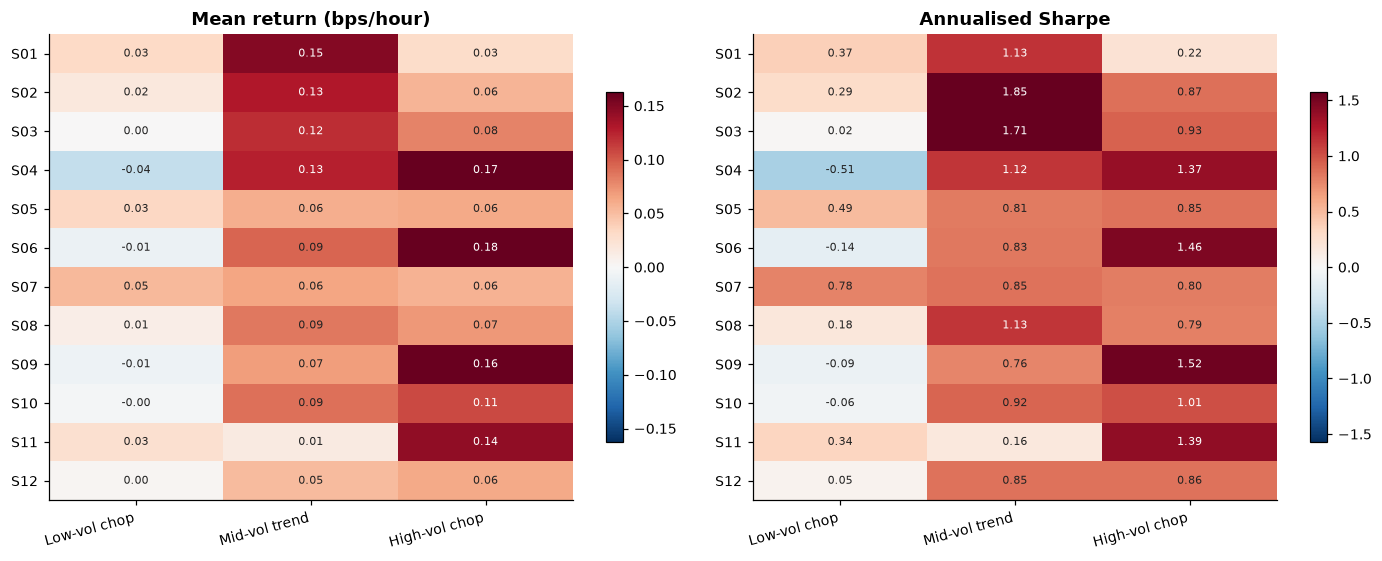

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, table, title, cmap, center in [
    (axes[0], mean_tbl, "Mean return (bps/hour)", "RdBu_r", 0),
    (axes[1], sharpe_tbl, "Annualised Sharpe", "RdBu_r", 0),
]:
    values = table.values
    vmax = np.nanpercentile(np.abs(values), 95)
    im = ax.imshow(values, cmap=cmap, vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(K_REGIMES), HMM_NAMES, rotation=15, ha="right")
    ax.set_yticks(range(len(STRATS)), STRATS)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            ax.text(j, i, f"{v:.2f}" if np.isfinite(v) else "–", ha="center", va="center",
                    fontsize=7.5, color="white" if abs(v) > 0.6 * vmax else "#222")
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.75)
savefig(fig, "07_strategy_regime_heatmaps")
plt.show()

**What to look for.** Ignore individual cells for a moment and look at *columns*: is one regime
systematically better for these strategies? Then look at *rows*: does a strategy's edge survive
all three regimes, or is it concentrated in one?

A strategy that only works in the calm state is not necessarily bad — but it is a **conditional
bet**, and it must be sized and allocated as one.

### 7.2 Rank stability — does the winner change?

If the ranking of strategies is stable across regimes, regime information adds little: just pick
the best strategy and hold it. If the ranking flips, there is a case for regime-conditioned
allocation. Spearman correlation between regime rank vectors quantifies this.

Rank by Sharpe within each regime (1 = best)


,Low-vol chop,Mid-vol trend,High-vol chop
S01,3,3,12
S02,5,1,7
S03,8,2,6
S04,12,5,4
S05,2,10,9
S06,11,9,2
S07,1,8,10
S08,6,4,11
S09,10,11,1
S10,9,6,5


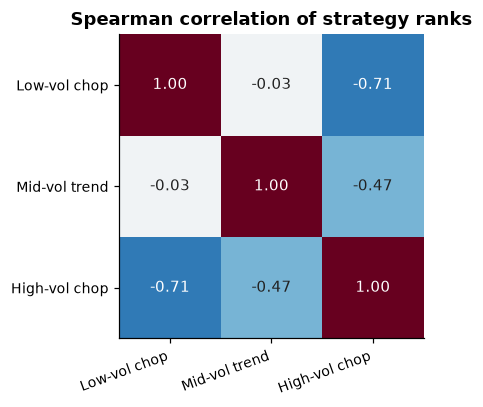

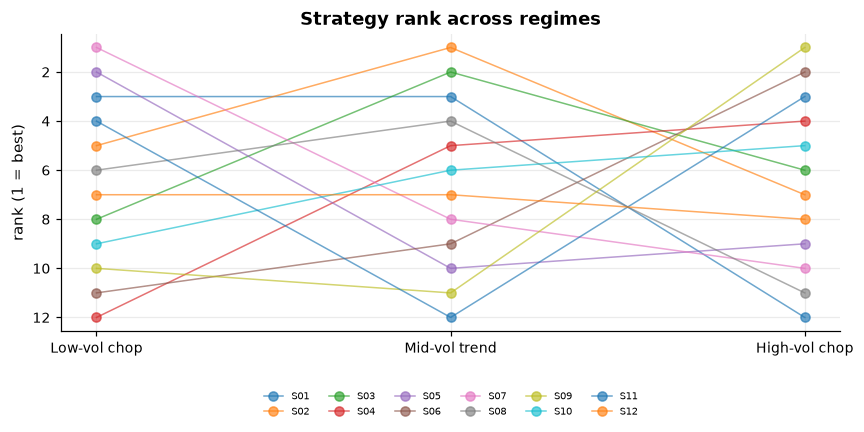

In [30]:
ranks = sharpe_tbl.rank(axis=0, ascending=False)
print("Rank by Sharpe within each regime (1 = best)")
display(ranks.astype(int))

rank_corr = ranks.corr(method="spearman")
fig, ax = plt.subplots(figsize=(4.8, 3.8))
im = ax.imshow(rank_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(K_REGIMES), HMM_NAMES, rotation=20, ha="right")
ax.set_yticks(range(K_REGIMES), HMM_NAMES)
for i in range(K_REGIMES):
    for j in range(K_REGIMES):
        ax.text(j, i, f"{rank_corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(rank_corr.iloc[i, j]) > 0.6 else "#222")
ax.set_title("Spearman correlation of strategy ranks")
ax.grid(False)
savefig(fig, "07_rank_correlation")
plt.show()

# rank movement: from calm to crisis
fig, ax = plt.subplots(figsize=(8, 4.2))
for name in STRATS:
    ax.plot(range(K_REGIMES), ranks.loc[name].values, "o-", lw=1, alpha=0.65, label=name)
ax.set_xticks(range(K_REGIMES), HMM_NAMES)
ax.invert_yaxis()
ax.set_ylabel("rank (1 = best)")
ax.set_title("Strategy rank across regimes")
ax.legend(ncol=6, fontsize=6.5, loc="lower center", bbox_to_anchor=(0.5, -0.32))
savefig(fig, "07_rank_paths")
plt.show()

### 7.3 Is any of this distinguishable from noise?

We attach a **circular block bootstrap** confidence interval to every strategy × regime mean
return. Blocks of 24 hours preserve intraday dependence; 300 resamples give a 95% interval.

Cells whose interval excludes zero are the only ones worth a second look — and even those need
an out-of-sample check, because we are scanning 36 cells at once.

In [31]:
def block_bootstrap_mean(x: np.ndarray, block: int = 24, n_boot: int = 300,
                         seed: int = 0) -> tuple[float, float]:
    """95% CI for the mean, resampling circular blocks of `block` observations."""
    x = np.asarray(x, dtype=float)
    T = len(x)
    if T < block * 2:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(T / block))
    offsets = np.arange(block)
    means = np.empty(n_boot)
    for b in range(n_boot):
        starts = rng.integers(0, T, size=n_blocks)
        idx = ((starts[:, None] + offsets[None, :]) % T).ravel()[:T]
        means[b] = x[idx].mean()
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(lo), float(hi)


boot_rows = {}
for name in STRATS:
    row = {}
    for k, rname in enumerate(HMM_NAMES):
        x = strat_h_ret.loc[HMM_LABELS == k, name].values
        lo, hi = block_bootstrap_mean(x, 24, 300, seed=k)
        row[rname] = f"{(x.mean()*1e4*BARS_PER_YEAR/1e4):+.1%} [{(lo*BARS_PER_YEAR):+.1%}, {(hi*BARS_PER_YEAR):+.1%}]"
    boot_rows[name] = row
boot_table = pd.DataFrame(boot_rows).T
print("Annualised mean return [95% block-bootstrap CI] by regime")
display(boot_table)

Annualised mean return [95% block-bootstrap CI] by regime


,Low-vol chop,Mid-vol trend,High-vol chop
S01,"+1.9% [-3.8%, +8.9%]","+9.0% [-2.2%, +20.8%]","+1.8% [-14.6%, +19.7%]"
S02,"+1.0% [-2.4%, +4.7%]","+7.8% [+0.9%, +15.2%]","+3.4% [-5.2%, +11.2%]"
S03,"+0.1% [-5.3%, +5.4%]","+7.2% [+1.2%, +14.7%]","+4.9% [-4.5%, +16.3%]"
S04,"-2.3% [-7.8%, +2.7%]","+7.6% [-1.2%, +17.3%]","+10.2% [-3.9%, +24.9%]"
S05,"+2.0% [-2.7%, +7.4%]","+3.6% [-3.4%, +10.1%]","+3.7% [-4.9%, +12.9%]"
S06,"-0.6% [-5.2%, +3.9%]","+5.7% [-3.7%, +16.2%]","+10.9% [-4.3%, +26.0%]"
S07,"+3.2% [-2.2%, +8.9%]","+3.9% [-2.7%, +9.6%]","+3.4% [-4.4%, +12.6%]"
S08,"+0.6% [-4.0%, +5.1%]","+5.2% [-1.6%, +13.0%]","+4.2% [-7.1%, +15.1%]"
S09,"-0.5% [-6.7%, +5.9%]","+4.1% [-3.6%, +12.0%]","+9.7% [-2.4%, +20.2%]"
S10,"-0.2% [-4.2%, +4.2%]","+5.4% [-4.3%, +14.5%]","+6.5% [-6.1%, +20.2%]"


The intervals are wide — wider than most people expect. That is the honest state of the
evidence with five years of hourly data. The practical lesson: **use regimes to manage risk and
diversification, not to chase the best strategy in each state.** A regime-conditional allocator
that chases noisy per-regime winners will mostly trade noise and pay costs.

> **Try it.** Recompute the tables using the K-means labels (`KM_LABELS`) instead of the HMM.
> Are the conclusions robust to the regime definition, or does the story change? If it changes,
> the "effect" was a property of the clustering, not of the market.

## 8. Does regime information improve allocation?

### The claim under test

> *Knowing the regime lets me allocate better than a static, regime-blind portfolio.*

This is a strong claim and it is easy to fake. We test it with a protocol that removes the
usual ways of cheating:

1. **No look-ahead in regimes.** The HMM is fitted on data before 2025 and applied online with
   the *filtered* probability. No Viterbi, no smoothing, no refitting on the future.
2. **No look-ahead in weights.** Weights on day `t` use returns and regimes up to `t`; they earn
   the return of day `t+1`.
3. **Costs.** Every change in weights pays turnover × cost in basis points.
4. **Long-only, fully invested (except the risk-off variant).** No leverage, no shorting.
5. **Out-of-sample only.** The scoreboard starts 2025-01-01.

### The methods

| Method | Idea |
|---|---|
| **Equal weight** | 1/N. The hardest baseline to beat. |
| **Inverse vol** | Risk parity without correlations; regime-blind. |
| **Static max-Sharpe** | Tangency portfolio fitted on the in-sample period, then frozen. |
| **Regime equal weight** | Equal-weight only the strategies with positive trailing P&L *in the current regime*. |
| **Regime inverse vol** | Same eligibility, inverse-vol weights. |
| **Regime max-Sharpe** | Shrunk tangency portfolio estimated from the current regime's history. |
| **Soft regime max-Sharpe** | Blend the per-regime tangency portfolios by the regime probabilities. |
| **Regime risk-off** | Equal weight, scaled down when the current regime is volatile. |

The first three are the control group. If a regime method cannot beat them after costs, the
regime information is not economically useful — even if it is statistically real.

In [32]:
# daily regime probabilities from the causal filter (last bar of each day)
regime_prob_h = pd.DataFrame(HMM_FILTER, index=features.index, columns=HMM_NAMES)

daily_index = strat_ret.index
regime_prob = (regime_prob_h.resample("1D").last()
               .reindex(daily_index).ffill().bfill())
regime_daily = pd.Series(regime_prob.values.argmax(1), index=daily_index)

print("daily returns:", strat_ret.shape, "| regime probs:", regime_prob.shape)
print("OOS days:", (daily_index >= pd.Timestamp("2025-01-01", tz="UTC")).sum())
display(regime_prob.tail(3).round(3))

daily returns: (1267, 12) | regime probs: (1267, 3)
OOS days: 490


,Low-vol chop,Mid-vol trend,High-vol chop
time,,,
2026-11-18 00:00:00+00:00,0.002,0.998,0.000
2026-11-19 00:00:00+00:00,1.000,0.000,0.000
2026-11-20 00:00:00+00:00,1.000,0.000,0.000


### 8.1 Weight functions

Each function receives:

* `hist` — the trailing window of daily strategy returns (a DataFrame),
* `hist_reg` — the regime label for each day in that window,
* `p_today` — the filtered regime probability vector for today.

It returns a weight vector of length N. **No function may look at `hist` beyond today.**

In [33]:
def _norm(w: np.ndarray) -> np.ndarray:
    w = np.clip(np.asarray(w, dtype=float), 0, None)
    s = w.sum()
    return w / s if s > 0 else np.full(len(w), 1.0 / len(w))


def shrunk_tangency(mu: np.ndarray, cov: np.ndarray, shrink: float = 0.5,
                    cap: float = 0.35) -> np.ndarray:
    """Long-only tangency approximation: w ~ Sigma^-1 mu, shrunk and capped.

    Shrinking the covariance towards its diagonal stabilises the inverse when the
    trailing window is short relative to the number of strategies.
    """
    n = len(mu)
    cov = (1 - shrink) * cov + shrink * np.diag(np.diag(cov))
    cov = cov + np.eye(n) * 1e-8
    try:
        w = np.linalg.solve(cov, mu)
    except np.linalg.LinAlgError:
        return np.full(n, 1.0 / n)
    w = np.clip(w, 0, None)
    if w.sum() <= 0:
        return np.full(n, 1.0 / n)
    w = w / w.sum()
    for _ in range(3):
        w = np.minimum(w, cap)
        w = w / w.sum()
    return w


def make_weight_functions(n: int):
    """Weight functions operate on NumPy arrays for speed.

    hist : (lookback, n) trailing daily returns
    hist_reg : (lookback,) regime label for each day in the window
    p : (n_states,) filtered probability today
    """

    def equal(hist, hist_reg, p):
        return np.full(n, 1.0 / n)

    def inverse_vol(hist, hist_reg, p):
        vol = hist.std(0)
        return _norm(1.0 / np.maximum(vol, 1e-9))

    def regime_equal(hist, hist_reg, p):
        state = int(np.argmax(p))
        sub = hist[hist_reg == state]
        if len(sub) < 20:
            return np.full(n, 1.0 / n)
        mu = sub.mean(0)
        good = mu > 0
        if good.sum() < 2:
            return np.full(n, 1.0 / n)
        w = np.zeros(n)
        w[good] = 1.0 / good.sum()
        return w

    def regime_inverse_vol(hist, hist_reg, p):
        state = int(np.argmax(p))
        sub = hist[hist_reg == state]
        if len(sub) < 20:
            return np.full(n, 1.0 / n)
        mu, vol = sub.mean(0), sub.std(0)
        good = (mu > 0) & (vol > 0)
        if good.sum() < 2:
            return np.full(n, 1.0 / n)
        w = np.zeros(n)
        w[good] = 1.0 / vol[good]
        return _norm(w)

    def regime_blend(hist, hist_reg, p):
        """Half regime-conditional, half equal weight: the cheapest defence against noise."""
        return 0.5 * regime_inverse_vol(hist, hist_reg, p) + 0.5 * np.full(n, 1.0 / n)

    def regime_tangency(hist, hist_reg, p):
        state = int(np.argmax(p))
        sub = hist[hist_reg == state]
        if len(sub) < 40:
            return np.full(n, 1.0 / n)
        mu, vol = sub.mean(0), sub.std(0)
        good = (mu > 0) & (vol > 0)
        if good.sum() < 3:
            return np.full(n, 1.0 / n)
        cov = np.cov(sub[:, good], rowvar=False)
        w = np.zeros(n)
        w[good] = shrunk_tangency(mu[good], np.atleast_2d(cov))
        return _norm(w)

    def soft_regime_tangency(hist, hist_reg, p):
        total = np.zeros(n)
        for k in range(len(p)):
            sub = hist[hist_reg == k]
            if len(sub) < 40 or p[k] < 1e-3:
                total += p[k] * np.full(n, 1.0 / n)
                continue
            mu, vol = sub.mean(0), sub.std(0)
            good = (mu > 0) & (vol > 0)
            if good.sum() < 3:
                total += p[k] * np.full(n, 1.0 / n)
                continue
            cov = np.cov(sub[:, good], rowvar=False)
            w = np.zeros(n)
            w[good] = shrunk_tangency(mu[good], np.atleast_2d(cov))
            total += p[k] * _norm(w)
        return _norm(total)

    def regime_risk_off(hist, hist_reg, p):
        state = int(np.argmax(p))
        sub = hist[hist_reg == state]
        base = np.full(n, 1.0 / n)
        if len(sub) < 20:
            return base
        state_vol = float(np.nanmean(sub.std(0)))
        overall_vol = float(np.nanmean(hist.std(0)))
        if state_vol <= 0:
            return base
        scale = np.clip(overall_vol / state_vol, 0.3, 1.0)
        return base * scale

    return {
        "Equal weight": equal,
        "Inverse vol": inverse_vol,
        "Static max-Sharpe": None,          # filled below
        "Regime equal weight": regime_equal,
        "Regime inverse vol": regime_inverse_vol,
        "Regime blend (50% EW)": regime_blend,
        "Regime max-Sharpe": regime_tangency,
        "Soft regime max-Sharpe": soft_regime_tangency,
        "Regime risk-off": regime_risk_off,
    }

### 8.2 The walk-forward engine

One loop, many methods. The engine is deliberately boring: it is easier to trust a backtest
whose code you can read in 20 lines.

In [34]:
OOS_START = pd.Timestamp("2025-01-01", tz="UTC")
LOOKBACK = 120          # trading days used to estimate weights
COST_BPS = 1.0          # per unit of turnover (1 bp = 0.01%)


def run_backtest(daily_ret: pd.DataFrame, regime_prob: pd.DataFrame,
                 weight_fn, start=OOS_START, lookback: int = LOOKBACK,
                 cost_bps: float = COST_BPS):
    """Walk-forward portfolio returns. Weights on t use data through t, earn t+1.

    Arrays are extracted once: the inner loop must never touch pandas.
    """
    dates = daily_ret.index
    R = daily_ret.to_numpy(dtype=float)
    P = regime_prob.to_numpy(dtype=float)
    start_idx = max(lookback, int(dates.searchsorted(start)))
    n = R.shape[1]
    w_prev = np.zeros(n)
    rets, turns, idx = [], [], []

    for t in range(start_idx, len(dates) - 1):
        lo = t - lookback + 1
        hist = R[lo:t + 1]
        hist_reg = P[lo:t + 1].argmax(1)
        p_today = P[t]

        w = np.asarray(weight_fn(hist, hist_reg, p_today), dtype=float)
        if w.sum() > 1.0 + 1e-9:          # never lever up
            w = w / w.sum()
        turnover = float(np.abs(w - w_prev).sum())
        cost = turnover * cost_bps / 1e4
        r = float(w @ R[t + 1]) - cost

        rets.append(r); turns.append(turnover); idx.append(dates[t + 1])
        w_prev = w

    return pd.Series(rets, index=idx, name="return"), pd.Series(turns, index=idx, name="turnover")


def static_max_sharpe(returns: pd.DataFrame, is_end=IS_END) -> np.ndarray:
    is_ret = returns.loc[returns.index < is_end]
    return shrunk_tangency(is_ret.mean().values, is_ret.cov().values)


weight_fns = make_weight_functions(len(STRATS))
static_w = static_max_sharpe(strat_ret)
weight_fns["Static max-Sharpe"] = lambda h, r, p: static_w

print("static max-Sharpe weights (in-sample fit):")
display(pd.Series(static_w, index=STRATS).round(3).to_frame("weight").T)

static max-Sharpe weights (in-sample fit):


,S01,S02,S03,S04,S05,S06,S07,S08,S09,S10,S11,S12
weight,0.001,0.305,0.226,0.000,0.066,0.062,0.084,0.048,0.015,0.000,0.042,0.152


### 8.3 Run the scoreboard

In [35]:
results = {}
turnovers = {}
for name, fn in weight_fns.items():
    ret, turn = run_backtest(strat_ret, regime_prob, fn)
    results[name] = ret
    turnovers[name] = turn

results = pd.DataFrame(results)
scoreboard = pd.DataFrame({
    name: perf_stats(results[name], freq=252, name=name) for name in results
}).T
scoreboard["Turnover (daily)"] = [turnovers[name].mean() for name in results]
scoreboard = scoreboard.sort_values("Sharpe", ascending=False)
display(scoreboard.round(3))

oos_days = len(results)
print(f"\nOOS period: {results.index.min().date()} -> {results.index.max().date()} "
      f"({oos_days} trading days, {oos_days/252:.1f} years)")

,CAGR,Vol,Sharpe,Sortino,MaxDD,Calmar,HitRate,Bars,Turnover (daily)
Regime risk-off,0.011,0.024,0.469,1.025,-0.031,0.366,0.337,489.000,0.062
Equal weight,0.011,0.025,0.463,0.991,-0.033,0.346,0.339,489.000,0.002
Inverse vol,0.010,0.025,0.430,0.954,-0.032,0.318,0.337,489.000,0.012
Static max-Sharpe,0.001,0.020,0.054,0.097,-0.042,0.022,0.329,489.000,0.002
Regime blend (50% EW),-0.003,0.024,-0.092,-0.193,-0.044,-0.057,0.309,489.000,0.363
Regime inverse vol,-0.016,0.027,-0.605,-1.098,-0.065,-0.250,0.249,489.000,0.723
Regime equal weight,-0.017,0.027,-0.623,-1.079,-0.066,-0.259,0.249,489.000,0.723
Soft regime max-Sharpe,-0.019,0.027,-0.669,-1.054,-0.068,-0.271,0.299,489.000,0.636
Regime max-Sharpe,-0.021,0.027,-0.745,-1.156,-0.069,-0.298,0.290,489.000,0.649



OOS period: 2025-01-03 -> 2026-11-20 (489 trading days, 1.9 years)


**Reading the default run.** The scoreboard usually shows three things at once:

* **Equal weight is hard to beat.** It is diversified, cheap, and has no parameters to overfit.
* **The regime-switching variants churn.** Look at `Turnover (daily)`: 0.5–0.7 means most of the
  book is replaced every day. At 1 bp per unit that is already ~1.5–2% a year of drag on a
  portfolio whose volatility is only ~2.5%.
* **The in-sample max-Sharpe portfolio collapses out of sample.** Its weights were fitted on
  2022–2024; by 2025 they are stale. That is the overfitting signature in its purest form.

The blend row is the useful diagnostic: halving the regime bets cuts turnover from roughly 0.7 to
0.35 and moves the Sharpe from clearly negative to roughly flat — better, but still below equal
weight. A signal that only works at full strength is not strong.

This is the honest, common outcome. The burden of proof is on the regime method, not on the
baseline.

### 8.4 Equity curves and drawdowns

A Sharpe table hides path dependency. Plot cumulative growth and underwater curves — a method
that wins on Sharpe but has a 30% drawdown is not automatically better.

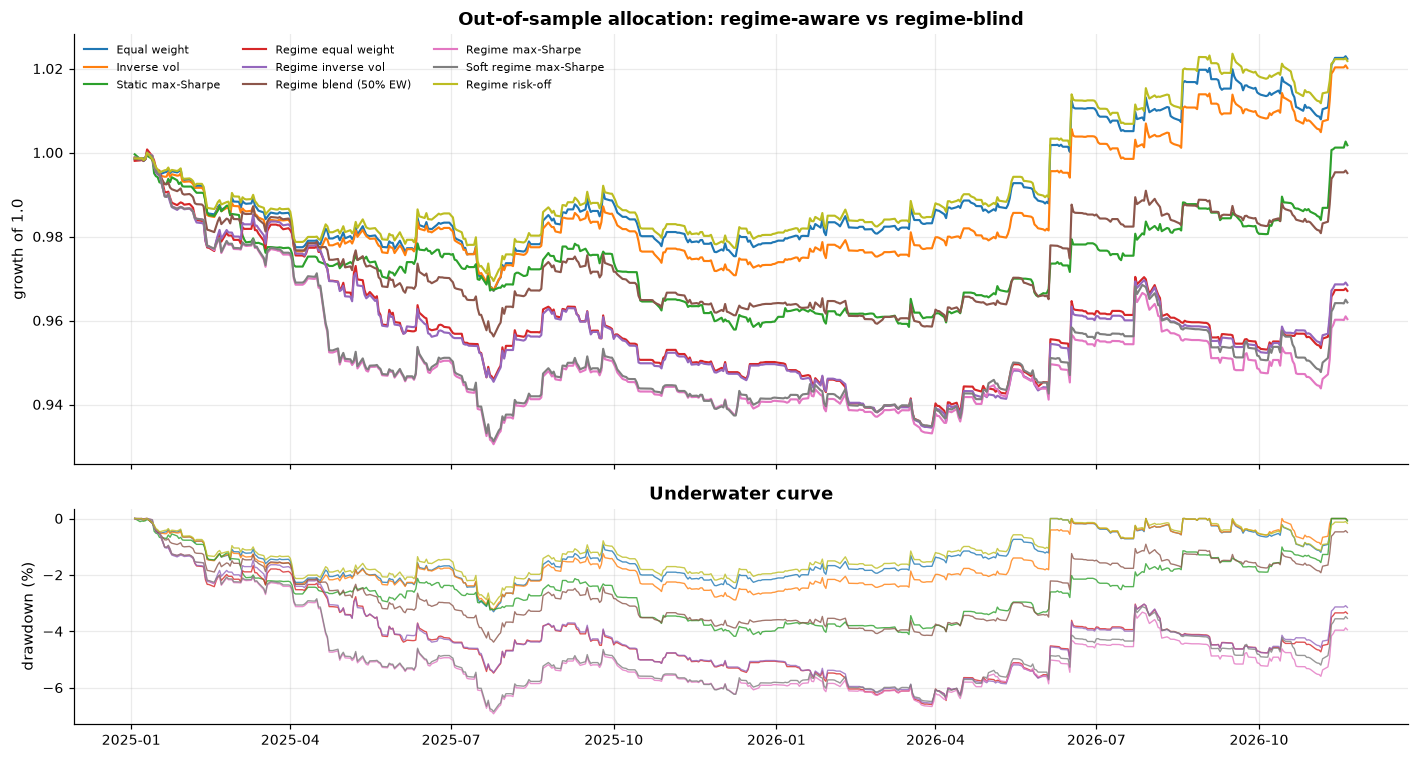

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
colors = plt.get_cmap("tab10")
for i, name in enumerate(results.columns):
    eq = (1 + results[name]).cumprod()
    axes[0].plot(eq.index, eq.values, lw=1.4, color=colors(i % 10), label=name)
    axes[1].plot(eq.index, (eq / eq.cummax() - 1).values * 100, lw=0.9,
                 color=colors(i % 10), alpha=0.8)

axes[0].set_ylabel("growth of 1.0")
axes[0].set_title("Out-of-sample allocation: regime-aware vs regime-blind")
axes[0].legend(ncol=3, fontsize=7.5)
axes[1].set_ylabel("drawdown (%)")
axes[1].set_title("Underwater curve")
savefig(fig, "08_allocation_equity")
plt.show()

### 8.5 Is the difference real? Paired block bootstrap

We compare each method to **equal weight** on the *same days*, resampling blocks of 20 days. This
preserves the dependence structure and answers: *if history had been slightly different, how
often would this method still beat EW?*

The output is a distribution of Sharpe differences. If the 95% interval contains zero, the
method is not distinguishable from EW — regardless of how good the point estimate looks.

In [37]:
def paired_block_bootstrap(r_a: pd.Series, r_b: pd.Series, block: int = 20,
                           n_boot: int = 2000, seed: int = 0):
    """Bootstrap the Sharpe difference (a - b) with circular blocks."""
    a = r_a.values
    b = r_b.values
    T = len(a)
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(T / block))
    offsets = np.arange(block)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        starts = rng.integers(0, T, size=n_blocks)
        idx = ((starts[:, None] + offsets[None, :]) % T).ravel()[:T]
        sa, sb = a[idx], b[idx]
        diffs[i] = (sa.mean() / sa.std() - sb.mean() / sb.std()) * np.sqrt(252)
    return diffs


ew = results["Equal weight"]
ci_rows = []
for name in results.columns:
    if name == "Equal weight":
        continue
    d = paired_block_bootstrap(results[name], ew)
    ci_rows.append({
        "method": name,
        "Sharpe diff vs EW": results[name].mean() / results[name].std() * np.sqrt(252)
                             - ew.mean() / ew.std() * np.sqrt(252),
        "CI low": np.percentile(d, 2.5),
        "CI high": np.percentile(d, 97.5),
        "P(beats EW)": (d > 0).mean(),
    })
ci_table = pd.DataFrame(ci_rows).set_index("method").sort_values("Sharpe diff vs EW", ascending=False)
display(ci_table.round(3))

,Sharpe diff vs EW,CI low,CI high,P(beats EW)
method,,,,
Regime risk-off,0.006,-0.190,0.141,0.552
Inverse vol,-0.033,-0.236,0.128,0.314
Static max-Sharpe,-0.409,-1.304,0.441,0.168
Regime blend (50% EW),-0.556,-1.216,-0.049,0.016
Regime inverse vol,-1.068,-2.219,-0.103,0.016
Regime equal weight,-1.086,-2.213,-0.159,0.010
Soft regime max-Sharpe,-1.133,-2.248,-0.121,0.016
Regime max-Sharpe,-1.209,-2.317,-0.210,0.008


**How to read it.** `P(beats EW)` is not a p-value in the classical sense, but it is the
question you actually care about: across plausible histories, how often did this rule win? A
method with `P = 0.55` and a wide interval is a coin flip. A method with `P = 0.97` and an
interval entirely above zero is worth a second study — on another symbol, another period, and
with realistic costs.

### 8.6 Cost sensitivity

Regime switching trades more. If the edge disappears at 3–5 bps of turnover cost, it was never
an edge — it was a way to pay spreads.

,0.000,1.000,2.000,5.000,10.000
Equal weight,0.465,0.463,0.461,0.455,0.444
Inverse vol,0.442,0.430,0.418,0.382,0.322
Static max-Sharpe,0.057,0.054,0.052,0.044,0.032
Regime equal weight,0.049,-0.623,-1.287,-3.196,-5.933
Regime inverse vol,0.077,-0.605,-1.279,-3.220,-6.007
Regime blend (50% EW),0.286,-0.092,-0.470,-1.588,-3.363
Regime max-Sharpe,-0.150,-0.745,-1.333,-3.022,-5.462
Soft regime max-Sharpe,-0.085,-0.669,-1.248,-2.920,-5.385
Regime risk-off,0.534,0.469,0.405,0.213,-0.107


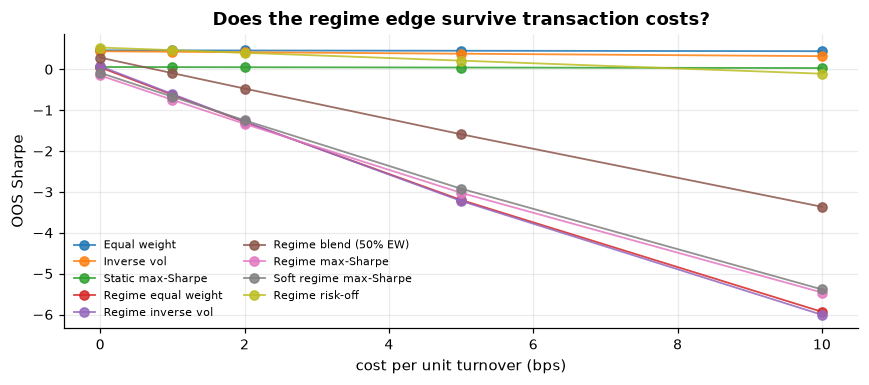

In [38]:
cost_grid = [0.0, 1.0, 2.0, 5.0, 10.0]
cost_rows = {}
for name, fn in weight_fns.items():
    row = {}
    for c in cost_grid:
        ret, _ = run_backtest(strat_ret, regime_prob, fn, cost_bps=c)
        row[c] = perf_stats(ret, freq=252)["Sharpe"]
    cost_rows[name] = row
cost_table = pd.DataFrame(cost_rows).T
display(cost_table.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
for name in cost_table.index:
    ax.plot(cost_table.columns, cost_table.loc[name], "o-", lw=1.2, label=name, alpha=0.85)
ax.set(xlabel="cost per unit turnover (bps)", ylabel="OOS Sharpe",
       title="Does the regime edge survive transaction costs?")
ax.legend(fontsize=7, ncol=2)
savefig(fig, "08_cost_sensitivity")
plt.show()

### 8.7 What would count as evidence?

A credible claim that "regimes improve allocation" needs **all** of the following:

1. The regime method beats EW **out of sample**, after costs, on a metric you chose *before*
   looking (not the best of six).
2. The improvement survives a **different regime definition** (K-means vs HMM, K=3 vs K=4).
3. The improvement survives a **different lookback** and rebalancing frequency.
4. The bootstrap interval excludes zero, or the effect is large enough to matter economically.
5. It replicates on **another symbol or asset class**, not just EURUSD 2022–2026.

Most published "regime switching" results fail at least three of these. Part 9 gives you the
machinery to run the checks yourself.

> **Try it.** Change `LOOKBACK` from 120 to 60 and re-run 8.3. Does the ranking survive? Then
> change `COST_BPS` to 5. Which methods are actually robust?

## 9. The hypothesis lab

You now have a complete pipeline. The point of this section is to make it **cheap to test your
own ideas** rather than re-wiring cells by hand.

### A hypothesis is a sentence with a number in it

Bad: *"volatility regimes should help."*
Good: *"A 3-state HMM on volatility + trend features will improve the out-of-sample Sharpe of a
regime-inverse-vol allocator by at least 0.2 versus equal weight, after 2 bps of turnover cost,
on EURUSD H1 2025–2026."*

The second version tells you exactly what to compute and what would prove you wrong.

### Candidate hypotheses for this project

| # | Hypothesis | How to test |
|---|---|---|
| H1 | More states improve fit but not allocation | `run_experiment(k=2,3,4)` |
| H2 | HMM beats K-means for allocation | `run_experiment(model="kmeans" / "hmm")` |
| H3 | Volatility alone is enough; trend features add nothing | `feature_set=["vol_24"]` |
| H4 | Regime information improves drawdowns more than Sharpe | compare `MaxDD`/`Sortino` |
| H5 | The edge dies after costs | `cost_bps=0, 2, 5` |
| H6 | The effect is concentrated in the high-vol state | condition performance by regime |
| H7 | Strategy rankings flip across regimes | Part 7 rank correlation |

Each experiment returns a row of metrics plus diagnostics, so you can compare many
specifications in one table — and see whether your conclusion is a property of the market or of
one arbitrary choice.

In [39]:
EXP_CACHE: dict = {}


def _daily_probs(P: np.ndarray) -> pd.DataFrame:
    frame = pd.DataFrame(P, index=features.index)
    return (frame.resample("1D").last()
            .reindex(strat_ret.index).ffill().bfill())


def run_experiment(k: int = 3, model: str = "hmm", feature_set=None,
                   cost_bps: float = 1.0, lookback: int = 120, seed: int = 7) -> dict:
    """Fit a regime model on IS, allocate OOS with regime-inverse-vol, return a metric row."""
    feature_set = tuple(feature_set) if feature_set else tuple(FEATURES)
    key = (k, model, feature_set, cost_bps, lookback, seed)
    if key in EXP_CACHE:
        return EXP_CACHE[key]

    X = features[list(feature_set)].values
    sc = StandardScaler().fit(X[is_mask])
    Zx = sc.transform(X)

    if model == "hmm":
        m = GaussianHMM(n_states=k, n_iter=80, seed=seed, var_floor=0.05, sticky=0.8)
        m.fit(Zx[is_mask], n_restarts=1, verbose=False)
        m.permute(np.argsort(m.mu[:, 0]))
        P = m.filter_proba(Zx)
        labels = P.argmax(1)
        extra = {"BIC": m.bic(Zx[is_mask]), "avg duration": float(m.expected_durations().mean())}
    elif model == "kmeans":
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(Zx[is_mask])
        centers = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=list(feature_set))
        order = np.argsort(centers.iloc[:, 0].values)
        remap = {int(o): i for i, o in enumerate(order)}
        labels = np.array([remap[int(x)] for x in km.predict(Zx)])
        P = np.eye(k)[labels]
        extra = {"BIC": np.nan, "avg duration": float(np.mean(run_lengths(labels)))}
    else:
        raise ValueError("model must be 'hmm' or 'kmeans'")

    prob_daily = _daily_probs(P)
    n = len(STRATS)

    def regime_inv_vol(hist, hist_reg, p):
        state = int(np.argmax(p))
        sub = hist[hist_reg == state]
        if len(sub) < 20:
            return np.full(n, 1.0 / n)
        mu, vol = sub.mean(0), sub.std(0)
        good = (mu > 0) & (vol > 0)
        if good.sum() < 2:
            return np.full(n, 1.0 / n)
        w = np.zeros(n)
        w[good] = 1.0 / vol[good]
        return _norm(w)

    ret, turn = run_backtest(strat_ret, prob_daily, regime_inv_vol, lookback=lookback,
                             cost_bps=cost_bps)
    st = perf_stats(ret, freq=252)
    row = {
        "K": k, "model": model, "features": "+".join(feature_set), "cost_bps": cost_bps,
        "Sharpe": st["Sharpe"], "CAGR": st["CAGR"], "MaxDD": st["MaxDD"],
        "Sortino": st["Sortino"], "turnover": float(turn.mean()),
        **extra,
    }
    EXP_CACHE[key] = row
    return row


print("run_experiment() ready - results are cached by specification.")

run_experiment() ready - results are cached by specification.


### 9.1 Demo: does the number of states matter?

We sweep K = 2, 3, 4 for both models. The comparison is deliberately unfair to complexity: each
extra state must earn its keep out of sample, after costs.

In [40]:
rows = []
for model in ["kmeans", "hmm"]:
    for k in [2, 3, 4]:
        rows.append(run_experiment(k=k, model=model, cost_bps=1.0))
sweep = pd.DataFrame(rows)

# equal-weight baseline for reference
ew_ret, ew_turn = run_backtest(strat_ret, regime_prob, weight_fns["Equal weight"])
ew_stats = perf_stats(ew_ret, freq=252)
print(f"Equal-weight baseline: Sharpe {ew_stats['Sharpe']:.2f}, MaxDD {ew_stats['MaxDD']:.1%}")
display(sweep.round(3))

Equal-weight baseline: Sharpe 0.46, MaxDD -3.3%


,K,model,features,cost_bps,Sharpe,CAGR,MaxDD,Sortino,turnover,BIC,avg duration
0,2,kmeans,vol_24+atr_pct+adx_14+trend_r2_48+er_24,1.000,-0.664,-0.021,-0.084,-1.190,0.738,NaN,19.911
1,3,kmeans,vol_24+atr_pct+adx_14+trend_r2_48+er_24,1.000,-0.986,-0.029,-0.092,-1.767,0.708,NaN,16.957
2,4,kmeans,vol_24+atr_pct+adx_14+trend_r2_48+er_24,1.000,-1.162,-0.037,-0.092,-2.230,1.023,NaN,12.737
3,2,hmm,vol_24+atr_pct+adx_14+trend_r2_48+er_24,1.000,-0.181,-0.006,-0.069,-0.336,0.520,"225,581.556",57.755
4,3,hmm,vol_24+atr_pct+adx_14+trend_r2_48+er_24,1.000,-0.605,-0.016,-0.065,-1.098,0.723,"204,207.947",37.242
5,4,hmm,vol_24+atr_pct+adx_14+trend_r2_48+er_24,1.000,-2.002,-0.055,-0.118,-3.537,0.977,"192,557.168",24.810


### 9.2 Demo: feature ablation

If a model with volatility alone performs the same as the full feature set, the trend features
are decoration. Ablation is the cheapest way to find out what your model is actually using.

In [41]:
ablations = {
    "vol only": ["vol_24"],
    "vol + atr": ["vol_24", "atr_pct"],
    "vol + trend": ["vol_24", "trend_r2_48", "er_24"],
    "all five": FEATURES,
}
abl_rows = [run_experiment(k=3, model="hmm", feature_set=v, cost_bps=1.0)
            for v in ablations.values()]
abl = pd.DataFrame(abl_rows)
abl["label"] = list(ablations.keys())
display(abl[["label", "features", "Sharpe", "MaxDD", "Sortino", "avg duration", "BIC"]].round(3))

,label,features,Sharpe,MaxDD,Sortino,avg duration,BIC
0,vol only,vol_24,-0.349,-0.062,-0.590,46.266,"20,059.228"
1,vol + atr,vol_24+atr_pct,-0.236,-0.052,-0.481,45.280,"47,793.478"
2,vol + trend,vol_24+trend_r2_48+er_24,-1.891,-0.125,-3.346,30.842,"120,187.031"
3,all five,vol_24+atr_pct+adx_14+trend_r2_48+er_24,-0.605,-0.065,-1.098,37.242,"204,207.947"


### 9.3 Writing your own experiment

The pattern is always the same:

1. **State the prediction** (direction and minimum size) *before* running.
2. **Change one thing** — features, K, model, costs, lookback, rebalance frequency.
3. **Record the result in a table**, including the specifications that failed.
4. **Count your attempts.** If you tried 20 variants and kept the best, your Sharpe is inflated
   by roughly $\sqrt{2\log 20}$ — the deflated-Sharpe problem. Report the whole table, not the
   winner.

Two extensions worth building yourself:

* **Refit schedule** — refit the HMM every quarter on an expanding window instead of freezing
  it. Does the online filter drift?
* **Regime-conditional vol targeting on the asset** — instead of switching strategies, scale
  exposure to EURUSD by the predicted regime volatility. Compare to plain vol targeting.

> **Try it.** Run `run_experiment(k=3, model="hmm", cost_bps=5.0)`. If the Sharpe falls below
> the equal-weight baseline, you have learned more than any positive result would teach you.

## 10. The playbook — what to keep, what to check, what to build next

### 10.1 What you actually built

A complete, honest regime-research pipeline:

* a clean UTC OHLCV store and a data audit;
* five economically motivated features, computed without look-ahead;
* a K-means partition with k-selection, stability testing and label ordering;
* a Gaussian HMM from scratch — forward–backward, Baum–Welch, Viterbi, filtering;
* a regime profile with significance tests and duration analysis;
* a mark-to-market reconstruction of 12 real MT5 strategies from raw deals;
* a strategy × regime performance map with block-bootstrap intervals;
* a walk-forward allocator with costs, seven methods, and paired bootstrap inference;
* an experiment harness for your own hypotheses.

### 10.2 The look-ahead checklist

Run this list against any regime strategy before you believe it:

- [ ] Features use only bars up to `t` (no centred windows, no negative shifts).
- [ ] The scaler is fitted on the training period only.
- [ ] Regime labels used for trading are **filtered**, not smoothed/Viterbi.
- [ ] Model parameters are fitted before the evaluation window.
- [ ] Weights on day `t` are applied to day `t+1` returns.
- [ ] Costs are charged on turnover, not just on trades.
- [ ] The strategy universe was chosen without knowing the evaluation period.
- [ ] The reported metric was chosen before looking at the results.

### 10.3 The five ways regime research fails

1. **The regimes are data bugs.** Clusters driven by a feed outage, a price spike, or a timezone
   shift. *Fix: audit first, winsorise, plot every state.*
2. **The regimes are a calendar.** One state exists only in 2022. *Fix: compare in-sample and
   out-of-sample shares; require the state to recur.*
3. **The edge is a label artefact.** Smoothed labels "predict" the past. *Fix: filter only.*
4. **The edge is noise.** 36 strategy × regime cells, one looks great. *Fix: bootstrap, correct
   for multiple testing, pre-register the cell.*
5. **The edge is costs.** The strategy switches every two days and pays 5 bps each time. *Fix:
   cost sensitivity; report net, never gross.*

### 10.4 What I would build next

| Extension | Why it matters |
|---|---|
| **Refit the HMM quarterly** | Tests whether frozen parameters decay; mirrors production. |
| **More assets** | A regime model that only works on EURUSD is a story about EURUSD. |
| **Macro / cross-asset features** | Rates, VIX, credit spreads often define regimes better than price alone. |
| **Hierarchical HMM / HSMM** | Explicit duration modelling; regimes with memory. |
| **Change-point detection** | Complements HMM: finds structural breaks without a fixed K. |
| **Regime-conditional risk budgeting** | Usually more robust than regime-conditional return chasing. |
| **Deflated Sharpe / PBO** | Quantifies how much of your result is selection. |

### 10.5 Glossary

| Term | Meaning |
|---|---|
| **Regime** | A persistent market environment with distinct conditional distributions. |
| **Latent state** | An unobserved variable the model infers from observables. |
| **Transition matrix** | `A[i,j] = P(state tomorrow = j | state today = i)`. |
| **Emission** | The distribution of observed features given a state. |
| **Baum–Welch** | EM algorithm for fitting HMM parameters. |
| **Viterbi** | Most likely state path given the whole sequence (uses the future). |
| **Filtered probability** | `P(state_t | data up to t)` — the only causal one. |
| **Smoothed probability** | `P(state_t | all data)` — for analysis, not trading. |
| **ARI** | Adjusted Rand Index: agreement between two clusterings, chance-corrected. |
| **BIC** | Penalised likelihood for model selection; lower is better. |
| **Turnover** | Sum of absolute weight changes; drives transaction costs. |
| **Deflated Sharpe** | Sharpe adjusted for the number of strategies tried. |
| **Survivorship bias** | Only winners survive into your dataset. |

### 10.6 Further reading

* Hamilton, J. D. (1989). *A New Approach to the Economic Analysis of Nonstationary Time Series
  and the Business Cycle.* Econometrica — the original regime-switching model.
* Ang, A. & Bekaert, G. (2002). *Regime Switches in Interest Rates.* JBES.
* Nystrup, P., Madsen, H., & Lindström, E. (2018). *Dynamic portfolio optimization across hidden
  market regimes.* Quantitative Finance.
* Wilder, J. W. (1978). *New Concepts in Technical Trading Systems* — ATR, ADX, RSI.
* Kaufman, P. J. (2013). *Trading Systems and Methods* — efficiency ratio.
* Bailey, D. H. & López de Prado, M. (2014). *The Deflated Sharpe Ratio.* Journal of Portfolio
  Management.
* López de Prado, M. (2018). *Advances in Financial Machine Learning* — backtest overfitting,
  purged cross-validation.

### 10.7 Reproducibility

Everything above is seeded (`CONFIG["seed"] = 7`) and depends only on the two CSV files in
`data/`. Figures are written to `figures/`, tables to `outputs/`. If you change a parameter,
change it in `CONFIG` or in the experiment call — not in five places — so the notebook remains a
record of what you actually ran.

> The final cell writes the key tables to `outputs/`. Keep them next to your research notes:
> six months from now, the table is the only reliable memory of what you tested.

In [42]:
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

exports = {
    "regime_profile": profile,
    "strategy_regime_sharpe": sharpe_tbl,
    "strategy_regime_mean_bps": mean_tbl,
    "allocation_scoreboard": scoreboard,
    "allocation_bootstrap": ci_table,
    "experiment_sweep": sweep,
    "feature_ablation": abl,
}
for name, table in exports.items():
    table.to_csv(OUT / f"{name}.csv")

print("written to", OUT)
for name in exports:
    print("  -", f"{name}.csv")
print("\nfigures:", len(list(FIG.glob('*.png'))), "PNG files in", FIG)

written to C:\Users\DAT\Desktop\VSCode\Quant_Learning\outputs
  - regime_profile.csv
  - strategy_regime_sharpe.csv
  - strategy_regime_mean_bps.csv
  - allocation_scoreboard.csv
  - allocation_bootstrap.csv
  - experiment_sweep.csv
  - feature_ablation.csv

figures: 21 PNG files in C:\Users\DAT\Desktop\VSCode\Quant_Learning\figures


---

**Final thought.** The most valuable output of this notebook is not a Sharpe ratio. It is the
habit of asking *"what would have to be true for this result to be fake?"* — and then running
that test. Regimes are real; regime *timing edges* are rare. The difference is almost always in
the protocol, not in the model.

If you want to go further, pick one hypothesis from Part 9, write the prediction down, and run
it on a symbol you have never looked at. That is the closest thing to an out-of-sample test a
researcher can give themselves.